# Beyond the Dashboard: AI untuk Perencanaan Akademik IPB
## Workbook langkah demi langkah - dua lab terintegrasi

**Tingkat:** pemula hingga menengah | **Total praktik:** 180 menit | **Bahasa:** Indonesia

Selamat datang! Kita tidak mulai dari *memilih algoritma*. Kita mulai dari **masalah nyata yang ingin dijawab pengelola kampus**.

> **Misi workshop:** (1) Mencocokkan kebutuhan mata kuliah dengan dosen yang tersedia, dan (2) membantu dosen wali menawarkan dukungan lebih awal serta menyiapkan rekomendasi KRS yang sesuai aturan.

| Lab | Pertanyaan yang akan dijawab | Hasil akhir |
|---|---|---|
| **Lab 1 - Demand & Supply (90 menit)** | Berapa pendaftaran semester berikutnya? Apakah dosen dan section cukup? | Perencanaan section, estimasi kapasitas dosen per prodi, dan analisis gap |
| **Lab 2 - Student Success (90 menit)** | Siapa yang perlu ditawari bantuan? Mata kuliah apa yang relevan dan boleh diambil? | Model risiko DO, penjelasan SHAP, rekomendasi collaborative filtering |

**Penting:** semua data **sintetis/fiktif**. Nama dan aturan contoh bukan kebijakan resmi IPB. Skor risiko hanya membantu **memprioritaskan penawaran layanan secara rahasia**, tidak boleh dipakai untuk pemberian sanksi atau pembatasan KRS.

### Cara menggunakan workbook ini
1. Baca kotak **Tujuan** sebelum menjalankan kode.
2. Jalankan satu sel kode menggunakan `Shift + Enter`.
3. Baca kotak **Cara membaca hasil** sesudahnya. Cocokkan dengan output di laptopmu.
4. Kerjakan **Coba ubah** bersama tim (opsional saat waktu terbatas).
5. Setiap lab diakhiri dengan **satu keputusan dan satu batasan model**, bukan hanya satu angka.

> **Catatan:** angka evaluasi boleh dibahas di notebook. Di slide presentasi, peserta hanya mempelajari cara mengevaluasi, tanpa melihat hasil eksperimen terlebih dahulu.

### Agenda praktik dan target waktu

| Tahap | Durasi | Yang kita kerjakan |
|---|---:|---|
| 1A. Kenali data | 15 menit | Baca tabel dan cari bottleneck |
| 1B. Forecast kebutuhan mata kuliah | 30 menit | X/y, lag, training, baseline, MAE, forecast |
| 1C. Match dengan dosen | 30 menit | Hitung section, supply SKS per prodi, dan gap |
| 1D. Simulasi kondisi | 15 menit | Kapasitas dosen turun: pilih tindakan |
| 2A-B. Risiko DO + SHAP | 45 menit | Klasifikasi, evaluasi, XAI, support queue |
| 2C. Collaborative filtering + prasyarat | 30 menit | Kemiripan mata kuliah, filter KRS, Precision@3 |
| 2D. Executive challenge | 15 menit | Presentasi ringkas rekomendasi tim |

**Kamus mini:** `feature (X)` = informasi yang diketahui sebagai input; `target (y)` = jawaban historis untuk dilatih; `fit()` = proses mempelajari pola; `predict()` = menghasilkan estimasi; `holdout` = data masa depan yang disimpan untuk menguji model.

## Persiapan: pastikan folder dan Python siap

Letakkan file notebook **sejajar** dengan folder `data/` dari paket ZIP. Jangan membuka notebook langsung dari file ZIP.

Folder minimal:

```text
IPB_Workshop_Beginner_Friendly/
  IPB_2Labs_Guided_Beginner.ipynb
  data/
    course_demand.csv
    courses.csv
    student_term_snapshots.csv
    academic_history.csv
    ...
  outputs/   (terbentuk otomatis)
```

Jika paket Python belum terinstal, instal terlebih dahulu lewat terminal: `pip install -r requirements.txt`. Setelah itu restart kernel dan jalankan sel berikut.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Library machine learning dan evaluasi
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, roc_auc_score, average_precision_score
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from sklearn.inspection import permutation_importance
from sklearn.metrics.pairwise import cosine_similarity

# SHAP digunakan untuk menjelaskan output model risiko DO.
import shap

# Cari folder data di lokasi yang umum dipakai Jupyter/Colab.
DATA = next(
    (folder for folder in [Path('data'), Path('../data'), Path('/content/data')]
     if (folder / 'students.csv').exists()),
    None
)
if DATA is None:
    raise FileNotFoundError(
        "Folder data/ belum ditemukan. Ekstrak ZIP lengkap dan buka notebook dari folder yang benar."
    )

OUTPUT = Path('outputs')
OUTPUT.mkdir(exist_ok=True)
pd.set_option('display.max_columns', 30)

print('Data ditemukan di:', DATA.resolve())
print('Output akan disimpan di:', OUTPUT.resolve())
print('Versi pandas:', pd.__version__, '| SHAP:', shap.__version__)

Data ditemukan di: /Users/aries_fitriawan/Documents/Python Code/IPB_Workshop_Notebook_Baru/data
Output akan disimpan di: /Users/aries_fitriawan/Documents/Python Code/IPB_Workshop_Notebook_Baru/outputs
Versi pandas: 2.3.3 | SHAP: 0.49.1


/Users/aries_fitriawan/anaconda3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Berhenti sebentar - pahami 3 tipe keluaran

**Jangan tertukar:**

| Teknik | Menghasilkan apa? | Contoh di workshop |
|---|---|---|
| **Regresi** | Angka kontinu | Estimasi jumlah pendaftaran mata kuliah |
| **Klasifikasi** | Kategori atau probabilitas kategori | Kemungkinan status DO tercatat dalam 2 semester ke depan |
| **Collaborative filtering** | Urutan item yang relevan | Daftar mata kuliah yang memiliki pola kelulusan bersama |

Sistem akhir **tidak hanya ML**. Ada bagian berbasis aturan untuk memastikan prasyarat dan batas beban mengajar tetap dipenuhi.

---
# LAB 1 - Forecast Kebutuhan Mata Kuliah dan Kapasitas Dosen

**Sasaran akhir:** tabel yang menunjukkan untuk setiap mata kuliah: prediksi pendaftaran, jumlah section yang dibutuhkan, jumlah section yang dapat diberi dosen, dan demand yang belum terlayani.

## 1A. Data detective: memahami satu baris data (15 menit)

**Unit analisis:** satu baris `course_demand.csv` adalah **satu mata kuliah pada satu semester**. Karena itu `actual_enrollments` adalah jumlah pendaftaran mahasiswa-*mata kuliah*, **bukan jumlah mahasiswa unik di universitas**.

**Pertanyaan bisnis:** "Mata kuliah mana yang terlihat padat, dan mengapa kepadatan kelas saja belum cukup untuk menyimpulkan kebutuhan dosen?"

In [2]:
courses = pd.read_csv(DATA / 'courses.csv')
demand = pd.read_csv(DATA / 'course_demand.csv')
lecturers = pd.read_csv(DATA / 'lecturer_availability_term9.csv')
students = pd.read_csv(DATA / 'students.csv')

for name, df in [('courses', courses),('demand',demand),('lecturers',lecturers)]:
    print(f'{name:25} {df.shape[0]:>6,} baris | {df.shape[1]:>2} kolom')
display(demand.head(4))

courses                       80 baris | 10 kolom
demand                       720 baris | 10 kolom
lecturers                     80 baris |  9 kolom


,term,course_id,course_name,program,capacity,weekday,time_slot,offered,actual_enrollments,low_grade_rate
0,1,C101,Business Mathematics,Agribusiness Analytics,26,Wed,13:00,1,6.0,0.000000
1,1,C102,Introduction to Agribusiness,Agribusiness Analytics,28,Wed,13:00,1,7.0,0.142857
2,1,C103,Microeconomics,Agribusiness Analytics,31,Wed,13:00,1,7.0,0.142857
3,1,C104,Statistics for Business,Agribusiness Analytics,27,Thu,15:00,1,7.0,0.000000


**Cara membaca hasil:**
- `course_demand.csv`: riwayat per semester; `actual_enrollments` historis adalah nilai yang diamati.
- `courses.csv`: katalog mata kuliah dan batas `max_sections`.
- `lecturer_availability_term9.csv`: sisa SKS mengajar dosen pada semester perencanaan.
- `lecturer_course_eligibility.csv`: tersedia untuk pendalaman, **tetapi sengaja tidak dipakai pada simulasi 1C yang lebih sederhana**.

> **Coba cek:** `demand[['term', 'course_id', 'actual_enrollments']].head()` dan `demand.isna().sum()`. Apakah semua semester memiliki target yang sudah diketahui?

In [3]:
# Cek periode dan kekosongan target. Semester 9 adalah periode yang akan direncanakan.
ringkasan_data = demand.groupby('term').agg(
    jumlah_mata_kuliah=('course_id', 'nunique'),
    target_tersedia=('actual_enrollments', 'count')
)
display(ringkasan_data)
print('Duplikat mata kuliah-semester:', demand.duplicated(['term', 'course_id']).sum())

,jumlah_mata_kuliah,target_tersedia
term,,
1,80,80
2,80,80
3,80,80
4,80,80
5,80,80
6,80,80
7,80,80
8,80,80
9,80,0


Duplikat mata kuliah-semester: 0


**Insight:** jika `target_tersedia` lebih sedikit pada suatu semester, jangan mengisi target yang belum terjadi dengan angka nol. Nilai nol berarti *benar-benar tidak ada pendaftaran*, sedangkan `NaN` berarti **belum tersedia**.

,course_name,program,actual_enrollments,capacity,historical_utilization
616,Applied Research Methods,Environmental Informatics,31.0,12,2.58
636,Applied Research Methods,Data Science for Agriculture,37.0,15,2.47
577,Innovation Management,Agribusiness Analytics,32.0,13,2.46
613,Data Visualization,Environmental Informatics,30.0,13,2.31
570,Decision Analysis,Agribusiness Analytics,27.0,12,2.25
598,Responsible AI,Agricultural Technology,26.0,12,2.17
593,Data Visualization,Agricultural Technology,35.0,17,2.06
634,Operations Research,Data Science for Agriculture,27.0,14,1.93


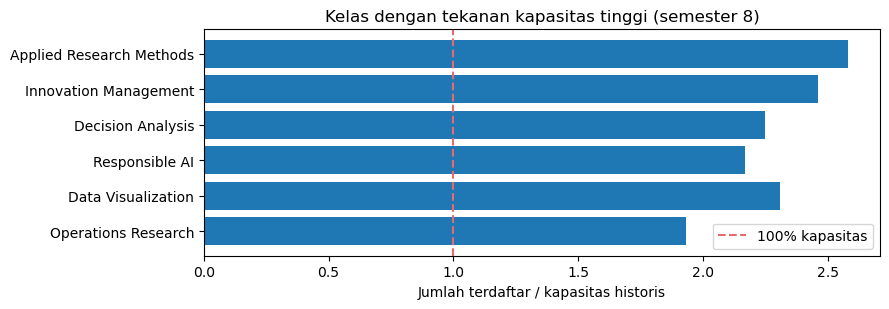

In [4]:
last_term = 8
recent = demand.loc[demand.term.eq(last_term)].copy()
recent['historical_utilization'] = (recent.actual_enrollments / recent.capacity).round(2)
display(recent[['course_name','program','actual_enrollments','capacity','historical_utilization']]
        .sort_values('historical_utilization',ascending=False).head(8))

plt.figure(figsize=(9,3.2))
g = recent.nlargest(8,'historical_utilization').iloc[::-1]
plt.barh(g.course_name, g.historical_utilization)
plt.axvline(1.0,ls='--',color='#E56B6F',label='100% kapasitas')
plt.xlabel('Jumlah terdaftar / kapasitas historis')
plt.title('Kelas dengan tekanan kapasitas tinggi (semester 8)')
plt.legend();plt.tight_layout();plt.show()

**Cara membaca visual:**
1. Garis putus-putus di rasio 1.0 artinya jumlah pendaftaran sama dengan **kapasitas historis satu penawaran**.
2. Rasio di atas 1.0 tidak otomatis berarti ada mahasiswa ditolak; data sintetis dapat menggambarkan lebih dari satu section.
3. Untuk mengidentifikasi demand yang *tidak tertampung*, kita masih perlu melihat forecast, aturan section, dan dosen yang tersedia.

**Pertanyaan untuk tim:** Jika satu mata kuliah penuh, apakah solusinya langsung membuka section baru? Data apa yang belum kita punya?

**Checkpoint 1A — Diskusi cepat**

Apakah kelas 100% penuh membuktikan seluruh permintaan sudah terpenuhi? **Tidak.** Pendaftaran historis bisa dibatasi kursi. Tanpa data *waitlist* dan permintaan KRS yang ditolak, model ini memprediksi **pendaftaran yang tercatat**, bukan seluruh *latent demand*. Sebutkan data tambahan yang perlu dikumpulkan untuk perencanaan riil.

## 1B. Melatih Model Forecast Kebutuhan Mata Kuliah (30 menit)

### Target pembelajaran
Setelah tahap ini, kamu bisa menjawab:
- Apa bedanya `X` (fitur) dan `y` (target)?
- Bagaimana membuat fitur histori tanpa memakai data masa depan?
- Bagaimana membuktikan bahwa model lebih berguna daripada tebakan sederhana?
- Bagaimana membuat prediksi untuk semester depan yang belum memiliki target?

**Contoh satu baris:** kita ingin memprediksi jumlah pendaftaran "Statistika" semester 8 (`y`). Kita boleh memakai jumlah pendaftaran semester 7 dan 6 (`lag_1`, `lag_2`), tetapi **tidak boleh memakai pendaftaran semester 8** sebagai masukan.

### Langkah 1. Tentukan X dan y

| Nama | Definisi | Contoh sederhana |
|---|---|---|
| **y = `actual_enrollments`** | Angka yang mau dipelajari model | 80 mahasiswa mendaftar suatu mata kuliah |
| **X = `lag_1`** | Pendaftaran mata kuliah yang sama pada t-1 | 75 |
| **X = `lag_2`** | Pendaftaran mata kuliah yang sama pada t-2 | 66 |
| **X = `avg_lag2`** | Rata-rata dua semester terakhir | 70.5 |
| **X = `odd_term`** | Penanda semester ganjil (1) atau genap (0) | 0 atau 1 |
| **X = `term_index`, `level`, `difficulty`** | Posisi waktu dan karakter mata kuliah | Beragam |
| **X = `capacity`** | Kapasitas yang *sudah direncanakan saat prediksi* | 30 kursi |

**Catatan penting:** memasukkan `capacity` dapat membuat model mempelajari **permintaan yang terealisasi/tercatat**, bukan seluruh minat mahasiswa. Jika ingin memperkirakan permintaan laten, universitas perlu data waitlist atau permintaan KRS yang ditolak.

### Langkah 2. Buat fitur histori menggunakan `shift()`

**Kenapa perlu `groupby()`?** Karena histori mata kuliah A tidak boleh tertukar dengan histori mata kuliah B. `shift(1)` berarti mengambil angka dari **baris semester sebelumnya untuk mata kuliah yang sama**.

Contoh:

| Semester | Pendaftaran historis (y) | `lag_1` | `lag_2` |
|---|---:|---:|---:|
| 5 | 60 | 55 | 49 |
| 6 | 66 | 60 | 55 |
| 7 | 75 | 66 | 60 |

Baris semester pertama dan kedua biasanya tidak punya semua lag; kita akan mengeluarkannya dari data training.

In [5]:
model_data = demand.merge(courses[['course_id','level','difficulty']], on='course_id')
model_data = model_data.sort_values(['course_id','term']).copy()
model_data['lag_1'] = model_data.groupby('course_id').actual_enrollments.shift(1)
model_data['lag_2'] = model_data.groupby('course_id').actual_enrollments.shift(2)
model_data['avg_lag2'] = (model_data.lag_1 + model_data.lag_2) / 2
model_data['odd_term'] = model_data.term % 2
model_data['term_index'] = model_data.term

# Semester 9 adalah periode masa depan dalam simulasi workshop.
# Sembunyikan target agar tidak bisa dipakai untuk evaluasi/training.
model_data.loc[model_data.term.eq(9), 'actual_enrollments'] = np.nan

display(model_data.loc[model_data.course_id.eq('C401'),
        ['term','course_name','lag_1','lag_2','avg_lag2','actual_enrollments']].head(9))

,term,course_name,lag_1,lag_2,avg_lag2,actual_enrollments
60,1,Intro to Programming,NaN,NaN,NaN,9.0
140,2,Intro to Programming,9.0,NaN,NaN,17.0
220,3,Intro to Programming,17.0,9.0,13.0,11.0
300,4,Intro to Programming,11.0,17.0,14.0,29.0
380,5,Intro to Programming,29.0,11.0,20.0,33.0
460,6,Intro to Programming,33.0,29.0,31.0,27.0
540,7,Intro to Programming,27.0,33.0,30.0,12.0
620,8,Intro to Programming,12.0,27.0,19.5,15.0
700,9,Intro to Programming,15.0,12.0,13.5,NaN


**Baca tabel setelah sel ini:**
- Apakah `lag_1` pada term 7 sama dengan target term 6?
- Apakah `lag_2` pada term 7 sama dengan target term 5?
- Mengapa target semester 9 perlu disembunyikan sebelum forecasting?

> **Mini-check:** `shift(1)` bukan melakukan prediksi. Ini hanya menyiapkan informasi masa lalu sebagai fitur.

### Langkah 3 — Pisahkan data training dan testing (time-based holdout)

- **Train:** semester 3–7 (lag sudah tersedia).
- **Test:** semester 8 (disimpan untuk menguji kemampuan generalisasi model).
- **Forecast:** semester 9 (belum ada aktual).

> Mengacak baris secara random bisa membuat model mengevaluasi masa lalu dengan informasi dari semester yang lebih baru. Untuk deret waktu, urutan semester harus dijaga.

### Langkah 3. Pisahkan data berdasarkan WAKTU

**Training** adalah semester 3-7: model melihat X dan y untuk belajar.

**Testing (holdout)** adalah semester 8: model menerima X, menghasilkan estimasi, lalu kita bandingkan dengan y yang benar-benar terjadi. Model **tidak dilatih** menggunakan y semester 8.

**Inference** adalah semester 9: model menerima X, tetapi y tidak diketahui; outputnya digunakan untuk perencanaan.

Mengapa tidak acak baris? Karena prediksi ke depan harus diuji pada periode yang lebih baru. Mengacak periode dapat membuat evaluasi terlalu optimistis.

In [6]:
forecast_features = [
    'lag_1','lag_2','avg_lag2','odd_term',
    'term_index','level','difficulty','capacity'
]
target_col = 'actual_enrollments'

train = model_data.loc[model_data.term.between(3,7)].dropna(subset=forecast_features+[target_col]).copy()
test = model_data.loc[model_data.term.eq(8)].dropna(subset=forecast_features+[target_col]).copy()

X_train = train[forecast_features]
y_train = train[target_col]
X_test = test[forecast_features]
y_test = test[target_col]

print(f'X_train = {X_train.shape} | y_train = {y_train.shape}')
print(f'X_test  = {X_test.shape} | y_test  = {y_test.shape}')
print('Nama fitur yang dipelajari:', list(X_train.columns))
print('3 nilai target contoh:', y_train.head(3).to_list())
assert X_train.notna().all().all() and X_test.notna().all().all()

X_train = (400, 8) | y_train = (400,)
X_test  = (80, 8) | y_test  = (80,)
Nama fitur yang dipelajari: ['lag_1', 'lag_2', 'avg_lag2', 'odd_term', 'term_index', 'level', 'difficulty', 'capacity']
3 nilai target contoh: [22.0, 22.0, 39.0]


In [7]:
# Lihat contoh baris training agar jelas perbedaan fitur dan target.
contoh_ke = 0
print('X (fitur):')
display(X_train.iloc[[contoh_ke]])
print('y (target historis):', float(y_train.iloc[contoh_ke]))

X (fitur):


,lag_1,lag_2,avg_lag2,odd_term,term_index,level,difficulty,capacity
160,19.0,6.0,12.5,1,3,1,1.65,28


y (target historis): 22.0


**Cara membaca:** satu baris X berisi beberapa kolom informasi; y hanya berisi angka yang ingin diprediksi. Nama dan jumlah kolom X harus konsisten saat training dan inference.

### Langkah 4 — Latih model Random Forest

Random Forest = **gabungan banyak decision tree**. Setiap pohon belajar dari pola fitur historis, lalu prediksi tiap pohon dirata-ratakan untuk menghasilkan jumlah pendaftar.

`fit(X_train, y_train)` adalah momen model *belajar*. `predict(X_test)` menghasilkan prediksi untuk data yang tidak dipakai saat training.

### Langkah 4. Model belajar melalui `fit(X_train, y_train)`

**Random Forest** berisi banyak pohon keputusan kecil. Setiap pohon menyusun aturan dari data historis, dan hasil regresi digabung melalui rata-rata prediksi pohon.

Untuk workshop ini, cukup kenali 3 pengaturan:
- `n_estimators`: berapa banyak pohon yang dipakai.
- `max_depth`: batas kerumitan tiap pohon, untuk membantu mengendalikan overfitting.
- `min_samples_leaf`: minimal jumlah contoh di tiap daun pohon.

Belum perlu mengutak-atik hyperparameter. Kita mulai dengan konfigurasi yang sudah disiapkan agar fokus ke alur data dan evaluasi.

In [8]:
forecast_model = RandomForestRegressor(
    n_estimators=160,        # Jumlah decision tree
    max_depth=9,            # Batas kompleksitas pohon
    min_samples_leaf=2,     # Minimal baris per leaf
    random_state=42, n_jobs=-1
)
forecast_model.fit(X_train, y_train)

pred_test = forecast_model.predict(X_test)
print('✅ Model Random Forest sudah dilatih!')
print('Prediksi 5 mata kuliah:', np.round(pred_test[:5],1))

✅ Model Random Forest sudah dilatih!
Prediksi 5 mata kuliah: [21.1 21.1 20.9 20.1 22.2]


### Langkah 5 — Evaluasi prediksi sebelum dipercaya

Bandingkan dengan baseline sederhana: **seasonal naive** yang memprediksi semester t sama seperti semester t−2 (`lag_2`).

**MAE (Mean Absolute Error)** = rata-rata selisih absolut nilai aktual dan prediksi, dalam **satuan mahasiswa-mata-kuliah**. MAE 6 artinya rata-rata selisih sekitar 6 pendaftaran per mata kuliah—**bukan 6%**.

### Langkah 5. Evaluasi: apakah model layak dipercaya?

**Baseline** adalah tebakan sederhana yang harus dikalahkan model. Dalam latihan ini, baseline `seasonal naive` menebak pendaftaran term t menggunakan pendaftaran term t-2 (meniru pola ganjil/genap).

**MAE (Mean Absolute Error)** = rata-rata selisih absolut antara prediksi dan aktual. Satuannya **pendaftaran per mata kuliah**. Makin kecil umumnya makin baik; **MAE nol** berarti prediksi sempurna pada data yang diuji.

Contoh fiktif: aktual 60, prediksi 54, maka error absolut = 6. Untuk satu mata kuliah, prediksi bisa lebih tinggi atau lebih rendah dari aktual.

**Pertanyaan yang benar:** "Apakah error model lebih kecil daripada baseline pada semester uji, dan cukup kecil untuk memutuskan jumlah section?" Bukan sekadar "Apakah model berhasil menjalankan `.fit()`?"

Seasonal naive MAE: 11.22 students / course
Random Forest MAE:  5.96 students / course
Model lebih baik dari baseline? Ya


,course_name,program,actual_enrollments,prediction,absolute_error
623,Probability & Statistics,Data Science for Agriculture,6.0,23.1,17.1
631,AI Agriculture Capstone,Data Science for Agriculture,16.0,33.1,17.1
583,Process Statistics,Agricultural Technology,7.0,23.3,16.3
585,Food Quality Analytics,Agricultural Technology,11.0,27.0,16.0
560,Business Mathematics,Agribusiness Analytics,6.0,21.1,15.1
567,Agrifood Marketing,Agribusiness Analytics,11.0,24.6,13.6


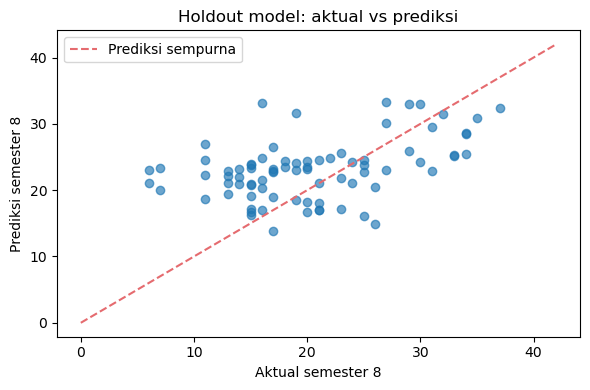

In [9]:
mae_baseline = mean_absolute_error(y_test, test['lag_2'])
mae_ml = mean_absolute_error(y_test, pred_test)

print(f'Seasonal naive MAE: {mae_baseline:.2f} students / course')
print(f'Random Forest MAE:  {mae_ml:.2f} students / course')
print('Model lebih baik dari baseline?' , 'Ya' if mae_ml < mae_baseline else 'Belum')

eval_forecast = test[['course_name','program',target_col]].copy()
eval_forecast['prediction'] = np.round(pred_test,1)
eval_forecast['absolute_error'] = (eval_forecast.actual_enrollments-eval_forecast.prediction).abs()
display(eval_forecast.nlargest(6,'absolute_error'))

plt.figure(figsize=(6,4))
plt.scatter(y_test, pred_test, alpha=.65)
vmax = max(float(y_test.max()),float(pred_test.max())) + 5
plt.plot([0,vmax],[0,vmax],'--',color='#E56B6F',label='Prediksi sempurna')
plt.xlabel('Aktual semester 8');plt.ylabel('Prediksi semester 8')
plt.title('Holdout model: aktual vs prediksi');plt.legend();plt.tight_layout();plt.show()

**Cara membaca output evaluasi:**
1. Bandingkan **MAE Random Forest dengan MAE baseline**. Angka yang lebih kecil berarti selisih prediksi rata-rata lebih kecil pada semester uji.
2. Pada grafik **aktual vs prediksi**, titik dekat garis diagonal adalah prediksi yang lebih akurat.
3. Buka tabel `absolute_error` terbesar: mata kuliah mana yang paling sulit diprediksi? Apakah bisa berpengaruh pada keputusan pembukaan section?

> **Insight akademik:** perhatikan akurasi per program studi dan per mata kuliah. Rata-rata kampus bisa bagus, tetapi kesalahan pada kelas wajib yang sangat padat tetap berisiko.

In [12]:
# Evaluasi per program: apakah ada area yang perlu dipantau lebih ketat?
evaluasi_program = (
    eval_forecast.groupby('program')
    .agg(jumlah_course=('course_name', 'count'),
         mae_per_course=('absolute_error', 'mean'))
    .sort_values('mae_per_course', ascending=False)
)
display(evaluasi_program.round(2))

,jumlah_course,mae_per_course
program,,
Agricultural Technology,20,6.50
Data Science for Agriculture,20,6.50
Agribusiness Analytics,20,5.92
Environmental Informatics,20,4.90


**Interpretasi:** `mae_per_course` di sini berarti rata-rata error absolut untuk mata kuliah dalam masing-masing program. Jika satu program lebih sulit diprediksi, jangan langsung menyimpulkan datanya buruk: cek jumlah observasi, seasonality, perubahan kurikulum, dan kelas yang hanya dibuka pada semester tertentu.

### Langkah 6 — Prediksi kebutuhan semester 9

Pada semester 9, `lag_1` berasal dari semester 8 dan `lag_2` dari semester 7. **Tidak ada target semester 9 yang digunakan untuk memprediksi.**

### Langkah 6. Forecast semester berikutnya

Saat membuat prediksi term 9:
- `lag_1` berasal dari pendaftaran term 8.
- `lag_2` berasal dari pendaftaran term 7.
- Kolom target term 9 belum ada; notebook **harus menolaknya** jika tanpa sengaja terbaca.

`forecast_demand` adalah estimasi angka yang mungkin terjadi, **bukan janji semua mahasiswa akan mendapat kursi**. Itu akan menjadi input kapasitas dosen pada 1C.

In [13]:
# Bangun fitur masa depan hanya dari data historis yang sudah selesai.
next_term = model_data.loc[model_data.term.eq(9)].copy()
for lag in [1,2]:
    prev = model_data.loc[model_data.term.eq(9-lag),['course_id','actual_enrollments']]
    prev = prev.rename(columns={'actual_enrollments':f'known_lag_{lag}'})
    next_term = next_term.merge(prev,on='course_id',how='left')
next_term['lag_1'] = next_term['known_lag_1']
next_term['lag_2'] = next_term['known_lag_2']
next_term['avg_lag2'] = (next_term.lag_1 + next_term.lag_2)/2
assert next_term[forecast_features].notna().all().all()
assert next_term.actual_enrollments.isna().all(), 'Target masa depan tidak boleh terlihat!'

next_term['forecast_demand'] = np.rint(
    forecast_model.predict(next_term[forecast_features])
).clip(min=0).astype(int)
next_term['single_section_shortage'] = (next_term.forecast_demand-next_term.capacity).clip(lower=0)

display(next_term[['course_name','forecast_demand','capacity','single_section_shortage']]
        .nlargest(10,'single_section_shortage'))
next_term.to_csv(OUTPUT/'forecast_term9_simulasi.csv',index=False)

,course_name,forecast_demand,capacity,single_section_shortage
10,Decision Analysis,33,10,23
17,Innovation Management,32,10,22
13,Data Visualization,31,11,20
38,Responsible AI,30,10,20
54,Operations Research,35,15,20
79,Project Studio,31,11,20
9,Business Intelligence,30,11,19
14,Operations Research,31,12,19
18,Responsible AI,29,10,19
35,Information Systems,29,10,19


**Checkpoint 1B - diskusi (2 menit):**
- Tunjukkan mata kuliah dengan `single_section_shortage` tertinggi.
- Jelaskan mengapa MAE perlu dibandingkan dengan baseline.
- Jelaskan mengapa `forecast_demand` masih belum cukup untuk memutuskan kelas bisa dibuka.

**Coba ubah (opsional):** ganti `max_depth=9` menjadi `max_depth=4`, lalu jalankan kembali dari sel training. Apa yang terjadi pada MAE semester uji? Apakah model menjadi terlalu sederhana (*underfitting*)?

## 1C. Dari Demand ke Kapasitas Section Dosen (30 menit) — **Versi Sederhana**

### Pertanyaan bisnis
**"Dari kebutuhan kelas yang diprediksi, berapa yang bisa kita layani dengan jumlah dosen yang tersedia?"**

Kita **tidak membuat jadwal per dosen**. Kita hanya menghitung kapasitas mengajar **per program studi (prodi)**. Cocok untuk workshop pemula: sedikit kode, tetapi output tetap relevan untuk perencanaan.

### Lima asumsi latihan (semuanya fiktif)
1. Setiap dosen hanya dihitung pada **satu prodi** dan dianggap dapat mengajar semua mata kuliah di prodinya. *Kompetensi spesifik tidak diperiksa.*
2. **Satu section membutuhkan 3 SKS mengajar** dan **satu dosen per section**. Seorang dosen bisa menangani lebih dari satu section jika SKS-nya cukup.
3. Batas `max_sections` dari katalog tetap berlaku.
4. **Prioritas:** mata kuliah dengan `forecast_demand` lebih tinggi mendapat alokasi kapasitas lebih dahulu.
5. Kita abaikan bentrok jadwal, ruangan, penugasan nyata, dan aturan beban kerja resmi.

Contoh: prediksi **85 pendaftar** dan **30 kursi/section** = perlu **3 section**. Jika `max_sections=2`, yang boleh dibuka hanya **2 section**. Jika kapasitas dosen prodi tinggal **1 section**, estimasi yang dapat ditangani hanya **1 section**.

**Alur:** forecast pendaftaran → kebutuhan section → kapasitas section dosen per prodi → alokasi sederhana → gap demand → opsi keputusan.

> **Penting:** `assigned_sections` di notebook ini berarti **estimasi section yang terdukung oleh kapasitas dosen prodi**, bukan penugasan mengajar bernama dosen yang sudah diverifikasi.

### Langkah 1 (±6 menit) — Hitung kebutuhan section per mata kuliah

Gunakan tabel hasil forecast `next_term` dari Lab 1B. Kita tinggal membulatkan kebutuhan kursi ke atas memakai `np.ceil()`.

| Kolom | Penjelasan |
|---|---|
| `forecast_demand` | Hasil prediksi jumlah pendaftaran suatu mata kuliah |
| `seats_per_section` | Jumlah kursi tiap section |
| `sections_needed` | Section yang dibutuhkan untuk semua prediksi pendaftar |
| `sections_allowed` | Section setelah memperhatikan batas `max_sections` |

Kita belum melihat data dosen pada langkah ini.

In [14]:
# DATA: hasil prediksi dari Lab 1B + katalog mata kuliah.
plan = next_term[['course_id', 'course_name', 'program',
                  'forecast_demand', 'capacity']].merge(
    courses[['course_id', 'max_sections']], on='course_id'
)
plan = plan.rename(columns={'capacity': 'seats_per_section'})

# ceil = bulatkan ke atas: 85 pendaftar / 30 kursi = 3 section.
plan['sections_needed'] = np.ceil(
    plan['forecast_demand'] / plan['seats_per_section']
).astype(int)
plan['sections_allowed'] = plan[['sections_needed', 'max_sections']].min(axis=1)

display(plan[['course_name', 'program', 'forecast_demand',
              'sections_needed', 'max_sections', 'sections_allowed']].head(8))

,course_name,program,forecast_demand,sections_needed,max_sections,sections_allowed
0,Business Mathematics,Agribusiness Analytics,15,1,3,1
1,Introduction to Agribusiness,Agribusiness Analytics,19,1,3,1
2,Microeconomics,Agribusiness Analytics,21,1,3,1
3,Statistics for Business,Agribusiness Analytics,24,2,3,2
4,Digital Agrimarket,Agribusiness Analytics,21,1,3,1
5,Business Data Analysis,Agribusiness Analytics,22,1,3,1
6,Supply Chain Planning,Agribusiness Analytics,26,2,3,2
7,Agrifood Marketing,Agribusiness Analytics,23,1,3,1


**Cara membaca:** kalau `sections_needed=3` dan `sections_allowed=2`, terdapat keterbatasan pembukaan kelas bahkan ketika dosen tersedia. Dalam kasus seperti itu, memanggil dosen tambahan saja **belum tentu** menyelesaikan masalah.

### Langkah 2 (±6 menit) — Berapa section dapat ditangani dosen setiap prodi?

Dari `lecturer_availability_term9.csv`, setiap dosen punya `available_teaching_sks` (sisa SKS mengajar). Untuk latihan ini, **3 SKS = kapasitas mengajar 1 section**.

- Dosen dengan **7 SKS tersedia** → `7 // 3 = 2 section` (sisa 1 SKS belum cukup untuk satu section).
- Dosen dengan **2 SKS tersedia** → `2 // 3 = 0 section`.
- Kita jumlahkan kapasitas section seluruh dosen dalam **masing-masing prodi**.

Operator Python `//` artinya **pembagian bulat**. Kita menghitung per dosen dahulu, baru menjumlahkan, supaya tidak menggabungkan pecahan SKS antarorang secara keliru.

In [16]:
SKS_PER_SECTION = 3  # ASUMSI latihan: 1 section memerlukan 3 SKS mengajar

lecturers['teachable_sections'] = (
    lecturers['available_teaching_sks'] // SKS_PER_SECTION
)

supply = lecturers.groupby('program', as_index=False).agg(
    jumlah_dosen=('lecturer_id', 'nunique'),
    total_sks_tersedia=('available_teaching_sks', 'sum'),
    section_dapat_diajar=('teachable_sections', 'sum')
)
display(supply)

,program,jumlah_dosen,total_sks_tersedia,section_dapat_diajar
0,Agribusiness Analytics,20,129,37
1,Agricultural Technology,20,133,37
2,Data Science for Agriculture,20,107,28
3,Environmental Informatics,20,131,37


**Cara membaca:** `section_dapat_diajar` adalah **batas atas sederhana** jumlah section yang bisa ditangani prodi. Angkanya belum memperhitungkan kemampuan khusus, jadwal, dan ruangan. Jika kebutuhan section di prodi lebih besar dari kapasitas ini, ada potensi gap kapasitas.

### Langkah 3 (±10 menit) — Bagikan kapasitas dosen ke mata kuliah

Kita sengaja menggunakan **satu loop pendek**, tanpa fungsi khusus yang panjang.

Strategi latihan (*greedy*):
1. Urutkan mata kuliah dalam setiap prodi, **demand terbesar dahulu**.
2. Catat berapa section yang masih tersedia di tiap prodi.
3. Untuk tiap mata kuliah, alokasikan yang lebih kecil di antara `sections_allowed` atau `sisa_sections`.
4. Kurangi sisa section prodi. Ulangi sampai semua mata kuliah diproses.

**Kita tidak memilih dosen satu per satu**. Ini sengaja agar peserta fokus pada hubungan demand, supply, dan keputusan. Strategi prioritas bisa kamu diskusikan (misalnya memprioritaskan mata kuliah wajib).

In [27]:
# 1) Mulai dari mata kuliah dengan demand terbesar pada masing-masing prodi.
staffing_plan = plan.sort_values(
    ['program', 'forecast_demand'], ascending=[True, False]
).copy()

# 2) Berapa section dosen yang tersedia pada setiap prodi?
sisa_sections = dict(zip(supply['program'], supply['section_dapat_diajar']))
staffing_plan['assigned_sections'] = 0

# 3) Alokasikan satu mata kuliah per baris.
for i, course in staffing_plan.iterrows():
    prodi = course['program']
    jumlah = min(course['sections_allowed'], sisa_sections[prodi])
    staffing_plan.loc[i, 'assigned_sections'] = jumlah
    sisa_sections[prodi] -= jumlah

# 4) Hitung kapasitas kursi dan gap pendaftaran.
staffing_plan['staffed_seats'] = (
    staffing_plan['assigned_sections'] * staffing_plan['seats_per_section']
)
staffing_plan['unserved_demand'] = (
    staffing_plan['forecast_demand'] - staffing_plan['staffed_seats']
).clip(lower=0)

display(staffing_plan.nlargest(10,'forecast_demand')[[
    'course_name', 'program', 'forecast_demand',
    'sections_needed', 'assigned_sections', 'unserved_demand'
]])

print('Prediksi pendaftaran:', int(staffing_plan.forecast_demand.sum()))
print('Kebutuhan section:', int(staffing_plan.sections_needed.sum()))
print('Estimasi section terdukung:', int(staffing_plan.assigned_sections.sum()))
print('Pendaftaran belum terlayani:', int(staffing_plan.unserved_demand.sum()))

,course_name,program,forecast_demand,sections_needed,assigned_sections,unserved_demand
54,Operations Research,Environmental Informatics,35,3,3,0
10,Decision Analysis,Agribusiness Analytics,33,4,3,3
17,Innovation Management,Agribusiness Analytics,32,4,3,2
36,Applied Research Methods,Agricultural Technology,32,2,2,0
37,Innovation Management,Agricultural Technology,32,2,2,0
73,Data Visualization,Data Science for Agriculture,32,3,3,0
76,Applied Research Methods,Data Science for Agriculture,32,3,3,0
77,Innovation Management,Data Science for Agriculture,32,2,2,0
56,Applied Research Methods,Environmental Informatics,32,2,2,0
13,Data Visualization,Agribusiness Analytics,31,3,3,0


Prediksi pendaftaran: 2006
Kebutuhan section: 148
Estimasi section terdukung: 136
Pendaftaran belum terlayani: 184


**Tiga angka penting untuk pimpinan:**
- `sections_needed` = kebutuhan section jika ingin melayani seluruh prediksi pendaftar.
- `assigned_sections` = estimasi section yang **mendapat porsi kapasitas dosen prodi** pada simulasi.
- `unserved_demand` = prediksi pendaftar yang belum memperoleh kursi menurut rencana sederhana ini.

**Contoh interpretasi:** jika forecast 85 orang, tersedia 1 section berkapasitas 30, maka estimasi gap = **55 pendaftaran**. Gap bukan bukti bahwa 55 mahasiswa pasti gagal mengambil kelas; masih perlu melihat daftar tunggu, alternatif section, dan kebijakan KRS.

### Langkah 4 (±6 menit) — Periksa hasil dan berikan rekomendasi

**Dua pertanyaan audit yang cukup untuk latihan ini:**
1. Apakah `assigned_sections` **tidak melampaui** `sections_allowed`?
2. Apakah total section yang dialokasikan di setiap prodi **tidak melebihi** kapasitas dosen prodi?

Kemudian bedakan dua masalah:
- **Batas pembukaan kelas:** `sections_needed > max_sections`.
- **Kapasitas dosen prodi:** `assigned_sections < sections_allowed`.

Satu mata kuliah bisa mengalami keduanya; label di tabel adalah **indikasi utama**, bukan diagnosis lengkap.

In [28]:
# Audit sederhana per prodi.
audit_program = staffing_plan.groupby('program', as_index=False).agg(
    section_dialokasikan=('assigned_sections', 'sum')
).merge(supply[['program', 'section_dapat_diajar']], on='program')

assert (audit_program.section_dialokasikan <= audit_program.section_dapat_diajar).all()
assert (staffing_plan.assigned_sections <= staffing_plan.sections_allowed).all()
print('Audit kapasitas section: LULUS')
display(audit_program)

# Identifikasi batasan utama untuk diskusi manajemen.
staffing_plan['planning_issue'] = 'Terpenuhi'
staffing_plan.loc[
    staffing_plan.sections_needed > staffing_plan.max_sections,
    'planning_issue'
] = 'Batas max_sections'
staffing_plan.loc[
    staffing_plan.assigned_sections < staffing_plan.sections_allowed,
    'planning_issue'
] = 'Kapasitas dosen prodi'

opsi = {
    'Terpenuhi': 'Monitor',
    'Batas max_sections': 'Tinjau izin pembukaan section tambahan',
    'Kapasitas dosen prodi': 'Tinjau redistribusi beban mengajar prodi'
}
staffing_plan['opsi_tindakan'] = staffing_plan.planning_issue.map(opsi)
display(staffing_plan.nlargest(8, 'unserved_demand')[[
    'course_name', 'unserved_demand', 'planning_issue', 'opsi_tindakan'
]])

# Simpan hasil untuk Lab 2 (rekomendasi KRS akan mengecek assigned_sections).
staffing_plan.to_csv(OUTPUT / 'demand_supply_plan_simulasi.csv', index=False)

Audit kapasitas section: LULUS


,program,section_dialokasikan,section_dapat_diajar
0,Agribusiness Analytics,37,37
1,Agricultural Technology,36,37
2,Data Science for Agriculture,28,28
3,Environmental Informatics,35,37


,course_name,unserved_demand,planning_issue,opsi_tindakan
72,Sustainable Systems,23,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
75,Information Systems,23,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
65,Machine Learning,22,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
68,Computer Vision for Crops,22,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
1,Introduction to Agribusiness,19,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
60,Intro to Programming,19,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
62,Data Fundamentals,19,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi
63,Probability & Statistics,17,Kapasitas dosen prodi,Tinjau redistribusi beban mengajar prodi


**Diskusi insight:** tidak semua gap memerlukan tambahan dosen. Jika batas `max_sections` yang menjadi masalah, tindakan yang lebih relevan adalah meninjau aturan pembukaan/ruang kelas. Jika kapasitas dosen prodi yang menjadi masalah, bahas redistribusi beban mengajar atau pilihan pengajaran tambahan. **Belum boleh menyebut keterbatasan spesialisasi dosen** sebagai penyebab, karena asumsi latihan mengabaikan kompetensi spesifik.

,program,forecast_demand,staffed_seats,unserved_demand
2,Data Science for Agriculture,502,481,145
0,Agribusiness Analytics,501,565,39
1,Agricultural Technology,500,630,0
3,Environmental Informatics,503,666,0


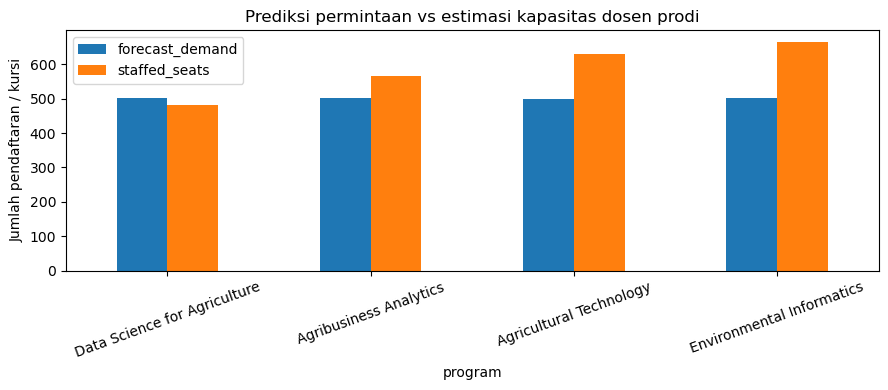

In [29]:
# Ringkasan per prodi dan visual sederhana.
by_program = staffing_plan.groupby('program', as_index=False).agg(
    forecast_demand=('forecast_demand', 'sum'),
    staffed_seats=('staffed_seats', 'sum'),
    unserved_demand=('unserved_demand', 'sum')
).sort_values('unserved_demand', ascending=False)

display(by_program)
by_program.plot.bar(x='program', y=['forecast_demand', 'staffed_seats'],
                    figsize=(9, 4), rot=20,
                    title='Prediksi permintaan vs estimasi kapasitas dosen prodi')
plt.ylabel('Jumlah pendaftaran / kursi')
plt.tight_layout()
plt.show()

## 1D. Team Challenge: kapasitas dosen berkurang (15 menit)

**Skenario:** ketersediaan SKS mengajar turun **20%**. Apakah demand–supply gap akan meningkat? Program studi mana paling terdampak?

Ulangi *langkah perhitungan yang sama* dengan SKS dosen yang lebih rendah. Ini sengaja ditulis ulang tanpa fungsi, supaya kamu bisa melihat langsung hubungan antara asumsi, kode, dan keputusan.

> **Coba ubah** `SUPPLY_LOSS = 0.20` menjadi `0.10` atau `0.30`, lalu jalankan kembali **hanya sel skenario**.

In [17]:
SUPPLY_LOSS = 0.20  # Coba ubah menjadi 0.10 atau 0.30

# 1) Hitung ulang kapasitas section per dosen setelah penurunan SKS.
shock_lecturers = lecturers.copy()
shock_lecturers['teachable_sections'] = (
    (shock_lecturers['available_teaching_sks'] * (1 - SUPPLY_LOSS)).astype(int)
    // SKS_PER_SECTION
)
shock_supply = shock_lecturers.groupby('program')['teachable_sections'].sum().to_dict()

# 2) Alokasi ulang mata kuliah menggunakan urutan prioritas yang sama.
shock_plan = plan.sort_values(['program', 'forecast_demand'], ascending=[True, False]).copy()
shock_plan['assigned_sections'] = 0
for i, course in shock_plan.iterrows():
    prodi = course['program']
    jumlah = min(course['sections_allowed'], shock_supply[prodi])
    shock_plan.loc[i, 'assigned_sections'] = jumlah
    shock_supply[prodi] -= jumlah

# 3) Hitung gap dan bandingkan dengan kondisi awal.
shock_plan['staffed_seats'] = shock_plan['assigned_sections'] * shock_plan['seats_per_section']
shock_plan['unserved_demand'] = (
    shock_plan['forecast_demand'] - shock_plan['staffed_seats']
).clip(lower=0)

scenario_compare = pd.DataFrame({
    'skenario': ['Normal', f'SKS dosen turun {SUPPLY_LOSS:.0%}'],
    'section_tersedia': [staffing_plan.assigned_sections.sum(), shock_plan.assigned_sections.sum()],
    'pendaftaran_belum_terlayani': [staffing_plan.unserved_demand.sum(), shock_plan.unserved_demand.sum()]
})
display(scenario_compare)
display(shock_plan.groupby('program').unserved_demand.sum()
        .sort_values(ascending=False).to_frame('gap_skenario'))

,skenario,section_tersedia,pendaftaran_belum_terlayani
0,Normal,136,184
1,SKS dosen turun 20%,99,828


,gap_skenario
program,
Agribusiness Analytics,276
Data Science for Agriculture,239
Agricultural Technology,162
Environmental Informatics,151


### Checkpoint 1C–1D — 3 pertanyaan untuk tiap tim

1. Mata kuliah/prodi mana yang memiliki **gap terbesar** pada kondisi normal?
2. Ketika kapasitas dosen turun 20%, **berapa tambahan pendaftaran yang tidak terlayani**? Dari prodi mana?
3. Apa tindakan manajemen yang paling masuk akal, **dan asumsi apa yang perlu diverifikasi dulu**?

**Batasan penting:** ini bukan algoritma *scheduling*, tidak menugaskan dosen satu per satu, tidak memeriksa kompetensi spesifik maupun ruangan/jadwal. Untuk implementasi sungguhan diperlukan data keahlian dosen, beban mengajar resmi, kelas wajib/pilihan, konflik waktu, dan kapasitas ruangan.

**Koneksi ke Lab 2:** `staffing_plan['assigned_sections']` akan dipakai hanya sebagai **indikator kapasitas kelas yang diproyeksikan tersedia** saat memfilter rekomendasi KRS, bukan jaminan tempat masih tersedia secara real-time.
**Jika ingin eksplorasi asumsi:** ubah `SKS_PER_SECTION = 3` menjadi `2` atau `4` pada Langkah 2, lalu jalankan ulang Langkah 2 sampai skenario. Diskusikan mengapa hasil berubah.

---
# LAB 2 - Student Retention dan Collaborative Course Recommendation

**Dua keputusan berbeda:**
- Model risiko DO membantu **menawarkan dukungan lebih awal**.
- Collaborative filtering membantu **mengurutkan rekomendasi mata kuliah**.

Keduanya harus dipisahkan: skor risiko tidak boleh digunakan untuk otomatis melarang seseorang mengikuti perkuliahan.

## 2A-B. Prediksi Risiko DO dan Kapasitas Dukungan (45 menit)

### Langkah 1. Pahami target, fitur, dan waktu prediksi

**Satu baris** pada `student_term_snapshots.csv` = **1 mahasiswa pada 1 snapshot akhir semester**.

**Target `y = do_within_next_2_terms`:** `1` bila status DO tercatat pada t+1 atau t+2 dalam data sintetis; `0` bila tidak, untuk snapshot yang dua semester observasinya sudah lengkap.

**Fitur `X`:** hanya informasi yang tersedia **pada akhir semester t**, misalnya IPK, perubahan IPK, kehadiran, SKS yang diambil/diperoleh, kemajuan studi, peringatan akademik, dan jeda registrasi. Hasil masa depan tidak boleh menjadi fitur.

| Contoh fitur | Makna untuk diskusi manajemen |
|---|---|
| `cumulative_gpa`, `gpa_change` | Kinerja akademik saat snapshot dan perubahannya |
| `earned_sks`, `progress_ratio` | Kemajuan studi, bukan kualitas pribadi mahasiswa |
| `attendance_rate` | Indikator keterlibatan yang mungkin memerlukan check-in |
| `registration_gap_recent` | Potensi kendala administratif yang perlu diverifikasi |
| `academic_warning_count` | Riwayat peringatan yang sudah tercatat |

> **Perhatian:** status DO memiliki konsekuensi sensitif. Gunakan model sebagai pendukung **penawaran bantuan secara privat, sukarela dan ditinjau dosen wali**, bukan diagnosis, hukuman, atau keputusan keluar studi.

In [18]:
retention = pd.read_csv(DATA/'student_term_snapshots.csv')
ret_features = [
    'cumulative_gpa','gpa_change','attendance_rate',
    'attempted_sks','earned_sks','progress_ratio',
    'low_grades_term','consecutive_low_gpa_terms',
    'academic_warning_count','registration_gap_recent',
    'semesters_enrolled'
]
ret_target = 'do_within_next_2_terms'

# Only snapshots <= term 6 have complete future t+1/t+2 labels in this dataset.
ret_train = retention.loc[retention.term.le(4)].dropna(subset=[ret_target]).copy()
ret_val   = retention.loc[retention.term.eq(5)].dropna(subset=[ret_target]).copy()
ret_test  = retention.loc[retention.term.eq(6)].dropna(subset=[ret_target]).copy()

for name,split in [('Train',ret_train),('Validation',ret_val),('Test',ret_test)]:
    print(f'{name:11}: n={len(split):4} | DO rate={split[ret_target].mean():.1%}')
print('X:',ret_features)
print('y:',ret_target)
assert set(ret_train.term).isdisjoint(set(ret_test.term))

Train      : n=1023 | DO rate=6.3%
Validation : n= 578 | DO rate=7.4%
Test       : n= 672 | DO rate=7.0%
X: ['cumulative_gpa', 'gpa_change', 'attendance_rate', 'attempted_sks', 'earned_sks', 'progress_ratio', 'low_grades_term', 'consecutive_low_gpa_terms', 'academic_warning_count', 'registration_gap_recent', 'semesters_enrolled']
y: do_within_next_2_terms


**Cara membaca train/validation/test:**
- **Train (term <=4):** dipakai untuk mempelajari koefisien model.
- **Validation (term 5):** dipakai untuk membandingkan pilihan fitur/parameter dan menghitung feature importance.
- **Test/holdout (term 6):** dipakai untuk penilaian akhir; jangan dijadikan tempat berulang-ulang memilih model.

Untuk simulasi ini, hanya snapshot sampai term 6 yang memiliki label **dua semester berikutnya** yang lengkap. Term 7-8 dapat dipakai untuk **scoring** dan tawaran dukungan, bukan untuk evaluasi target 2 semester yang belum matang.

**Catatan produksi:** waktu data benar-benar tersedia harus dihitung sampai label matang. Jika ada label atau periode yang tumpang tindih, gunakan pemisahan/embargo waktu sesuai prosedur kampus.

### Langkah 2 — Training klasifikasi (Logistic Regression)

Kita pakai **Logistic Regression** karena cepat, mudah dijelaskan, dan menghasilkan `predict_proba()` untuk mengurutkan prioritas **tawaran dukungan**, bukan memutuskan status mahasiswa.

`StandardScaler()` dipasang **di dalam pipeline** agar rata-rata/standar deviasi hanya dipelajari dari data train (hindari leakage).

### Langkah 2. Latih model klasifikasi

**Logistic Regression** adalah algoritma klasifikasi meski namanya memuat kata "regression". Ia mengeluarkan skor probabilitas kelas 1 melalui `predict_proba()`.

`StandardScaler()` menormalkan fitur numerik karena skala IPK, SKS, dan persentase kehadiran berbeda. `Pipeline` memastikan scaler hanya belajar dari data training.

In [19]:
ret_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=900,random_state=42)
)
ret_model.fit(ret_train[ret_features],ret_train[ret_target].astype(int))
ret_test['do_risk_score'] = ret_model.predict_proba(ret_test[ret_features])[:,1]

print('ROC-AUC (holdout term 6):',round(roc_auc_score(ret_test[ret_target],ret_test.do_risk_score),3))
print('PR-AUC  (holdout term 6):',round(average_precision_score(ret_test[ret_target],ret_test.do_risk_score),3))
print('Prevalensi DO simulasi:',round(ret_test[ret_target].mean(),3))
print('Catatan: PR-AUC perlu dibandingkan dengan prevalensi untuk data tidak seimbang.')

ROC-AUC (holdout term 6): 0.814
PR-AUC  (holdout term 6): 0.336
Prevalensi DO simulasi: 0.07
Catatan: PR-AUC perlu dibandingkan dengan prevalensi untuk data tidak seimbang.


### Langkah 3. Pahami evaluasi tanpa tertipu akurasi

- **ROC-AUC:** seberapa baik model memberi peringkat kasus positif di atas negatif pada berbagai ambang.
- **PR-AUC / Average Precision:** berguna jika kejadian DO lebih jarang; bandingkan dengan **prevalensi positif**.
- **Precision@K:** di antara K mahasiswa teratas yang ditinjau, berapa proporsi yang benar-benar berstatus positif pada data historis?
- **Recall@K:** dari semua kasus positif historis, berapa yang muncul dalam K teratas?

**Apa yang belum bisa dijawab metrik ini?** Apakah penawaran coaching *menyebabkan* risiko DO turun. Dampak intervensi memerlukan evaluasi terpisah.

In [20]:
# Contoh threshold hanya untuk memahami klasifikasi.
# Dalam program dukungan, kapasitas dosen wali/top-K biasanya lebih relevan.
THRESHOLD_DEMO = 0.50
predicted_class = (ret_test['do_risk_score'] >= THRESHOLD_DEMO).astype(int)
conf = confusion_matrix(ret_test[ret_target], predicted_class, labels=[0, 1])
confusion_table = pd.DataFrame(conf,
    index=['Aktual bukan DO', 'Aktual DO'],
    columns=['Prediksi bukan DO', 'Prediksi DO'])
display(confusion_table)
print('Precision pada threshold demo:', round(precision_score(
    ret_test[ret_target], predicted_class, zero_division=0), 3))
print('Recall pada threshold demo:', round(recall_score(
    ret_test[ret_target], predicted_class, zero_division=0), 3))

,Prediksi bukan DO,Prediksi DO
Aktual bukan DO,622,3
Aktual DO,45,2


Precision pada threshold demo: 0.4
Recall pada threshold demo: 0.043


**Cara membaca confusion matrix:** `False Positive` berarti mahasiswa diperkirakan berisiko namun status DO tidak tercatat dalam rentang observasi; `False Negative` berarti kasus DO yang tidak tertandai pada ambang ini. **Tidak ada ambang yang sempurna.** Karena itu gunakan human review dan cek kapasitas layanan.

### Opsional - kenalan dengan hyperparameter tuning (untuk tim yang lebih cepat)

`C` pada Logistic Regression adalah **hyperparameter** yang mengatur kekuatan regularisasi. Kita boleh membandingkan beberapa nilai C menggunakan **validation term 5**, tanpa melihat performa holdout term 6 untuk memilih pemenang.

**Bedakan:** `coef_` dipelajari model dari data; `C` ditentukan sebelum training.

In [21]:
# Latihan opsional: membandingkan C pada validation, tanpa mengubah model utama.
calon_C = [0.1, 1.0, 10.0]
hasil_validasi = []
for nilai_C in calon_C:
    kandidat = make_pipeline(StandardScaler(), LogisticRegression(
        C=nilai_C, max_iter=900, random_state=42))
    kandidat.fit(ret_train[ret_features], ret_train[ret_target].astype(int))
    peluang = kandidat.predict_proba(ret_val[ret_features])[:, 1]
    hasil_validasi.append({
        'C': nilai_C,
        'validation_average_precision': average_precision_score(ret_val[ret_target], peluang)
    })
display(pd.DataFrame(hasil_validasi).sort_values('validation_average_precision', ascending=False).round(3))
print('Model utama tetap memakai C default; percobaan ini hanya demonstrasi tuning.')

,C,validation_average_precision
0,0.1,0.228
1,1.0,0.224
2,10.0,0.222


Model utama tetap memakai C default; percobaan ini hanya demonstrasi tuning.


**Insight:** tidak ada satu hyperparameter yang selalu terbaik untuk seluruh kampus. Proses tuning yang baik memerlukan data validation yang tepat dan sebaiknya mengevaluasi stabilitas pada beberapa periode. **Jangan mengulang tuning pada holdout test** hanya agar angkanya terlihat bagus.

### Langkah 3 — Feature importance (global, Permutation Importance)

**Pertanyaan:** fitur mana yang paling membantu model membedakan kasus DO pada data yang belum dipakai training?

Metode **permutation importance**: acak satu fitur pada data *validation*, hitung penurunan ROC-AUC, ulangi beberapa kali. Penurunan makin besar → fitur makin berkontribusi terhadap kualitas prediksi model.

> **Interpretasi yang aman:** penting untuk *model* ≠ penyebab DO. Fitur yang berkorelasi (mis. earned SKS dan progress ratio) dapat berbagi kontribusi sehingga importance tidak selalu stabil.

### Langkah 4. Feature importance: fitur mana yang dipakai model?

**Permutation importance:** kita mengacak satu fitur di data validation lalu mengukur seberapa besar kinerja model menurun. Jika penurunannya besar, fitur itu **berkontribusi pada prediksi model**.

**Baca dengan hati-hati:** importance yang kecil bukan berarti variabelnya tidak penting secara klinis/akademik. Fitur saling berkorelasi bisa saling menggantikan, dan importance **tidak membuktikan sebab-akibat**.

,feature,roc_auc_drop,std
0,cumulative_gpa,0.035,0.006
1,gpa_change,0.019,0.013
8,academic_warning_count,0.010,0.005
2,attendance_rate,0.006,0.005
9,registration_gap_recent,0.006,0.005
7,consecutive_low_gpa_terms,0.003,0.002
3,attempted_sks,0.002,0.003
5,progress_ratio,0.000,0.001
4,earned_sks,-0.001,0.002
10,semesters_enrolled,-0.001,0.002


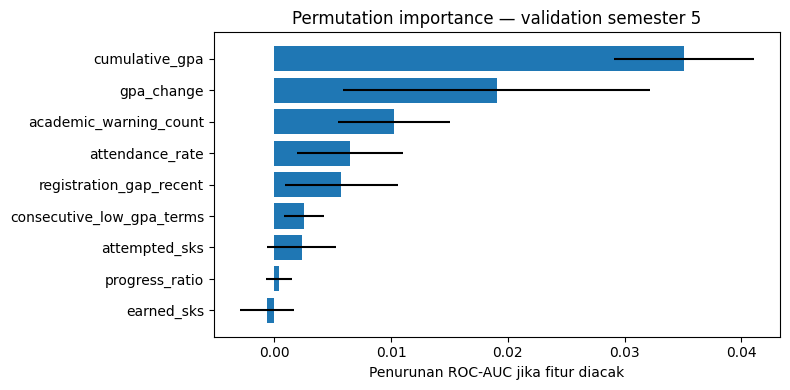

In [22]:
importance = permutation_importance(
    ret_model, ret_val[ret_features],ret_val[ret_target].astype(int),
    scoring='roc_auc',n_repeats=5,random_state=42
)
importance_table = pd.DataFrame({
    'feature':ret_features,
    'roc_auc_drop':importance.importances_mean,
    'std':importance.importances_std
}).sort_values('roc_auc_drop',ascending=False)
display(importance_table.round(3))

fig,ax=plt.subplots(figsize=(8,4))
show=importance_table.iloc[:9].iloc[::-1]
ax.barh(show.feature,show.roc_auc_drop,xerr=show['std'])
ax.set_xlabel('Penurunan ROC-AUC jika fitur diacak')
ax.set_title('Permutation importance — validation semester 5')
plt.tight_layout();plt.show()

**Cara membaca grafik feature importance:**
- Sumbu X: penurunan ROC-AUC setelah suatu fitur diacak (di validation).
- Nilai besar dan positif: mengacak fitur ini cenderung merusak kualitas ranking.
- Nilai dekat nol: pada pengujian ini, pengacakan tidak banyak mengubah hasil.
- Nilai negatif: bisa berupa variasi sampling atau pertanda metrik justru membaik setelah fitur diacak. Jangan dibaca sebagai dampak negatif kausal.

### Langkah 4 — XAI dengan SHAP: global dan individual

SHAP membantu menjawab **"fitur apa yang mendorong skor model pada contoh ini?"**

Untuk Logistic Regression yang menggunakan StandardScaler, kita menjelaskan model pada **fitur yang sudah distandardisasi**. Pada pendekatan `LinearExplainer`, nilai SHAP aditif dalam **skala log-odds**, *bukan* persentase probabilitas.

- Nilai SHAP **positif**: mendorong skor risiko model naik relatif baseline.
- Nilai SHAP **negatif**: mendorong skor risiko model turun relatif baseline.
- Penjelasan SHAP bersifat **asosiatif terhadap perilaku model**, bukan bukti bahwa mengubah suatu fitur akan mencegah DO.

### Langkah 5. XAI dengan SHAP: mengapa model memberi skor seperti itu?

**SHAP** menghitung kontribusi setiap fitur terhadap **output model relatif terhadap baseline**.

Ada dua cara membaca:

| Visual | Pertanyaan | Yang dilihat |
|---|---|---|
| **Beeswarm (global)** | Fitur apa yang biasanya banyak mengubah skor pada banyak mahasiswa? | Fitur di atas lebih dominan; posisi kiri/kanan menunjukkan arah kontribusi |
| **Waterfall (lokal)** | Mengapa contoh *satu* mahasiswa memperoleh skor tertentu? | Kontribusi positif/negatif dari baseline ke skor akhir |

Untuk model Logistic Regression ini, SHAP dijelaskan pada **skala log-odds**, bukan persen probabilitas. **SHAP bukan bukti bahwa mengubah suatu faktor akan mengubah kejadian DO**.

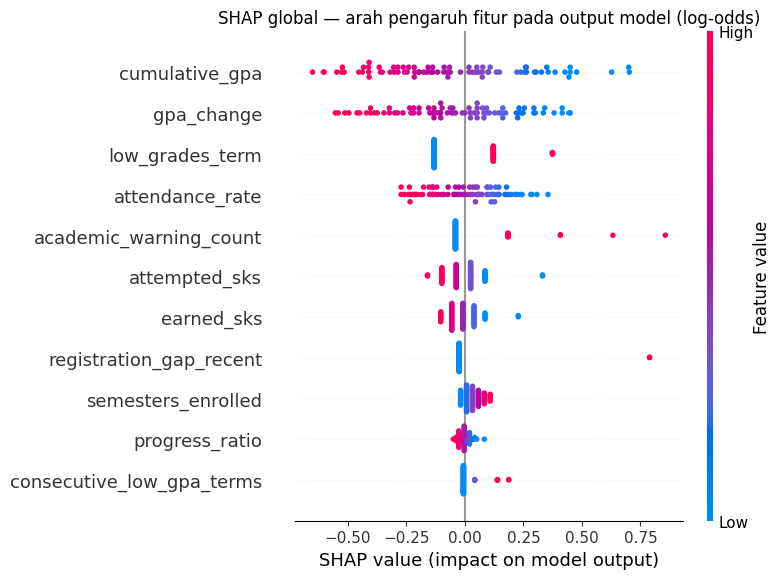

In [23]:
# Model logistic berada di dalam pipeline. SHAP menjelaskan hasil SETELAH scaling.
scaler = ret_model.named_steps['standardscaler']
logistic = ret_model.named_steps['logisticregression']

background = pd.DataFrame(
    scaler.transform(ret_train[ret_features].sample(n=min(200,len(ret_train)),random_state=42)),
    columns=ret_features
)
explain_sample = ret_test.sample(n=min(80,len(ret_test)),random_state=42)
X_explain_scaled = pd.DataFrame(scaler.transform(explain_sample[ret_features]),columns=ret_features)

explainer = shap.LinearExplainer(logistic,background)
shap_values = explainer(X_explain_scaled)

# Global: warna menunjukkan nilai fitur standardized, panjang SHAP menunjukkan arah dampak model.
shap.plots.beeswarm(shap_values,max_display=11,show=False)
plt.title('SHAP global — arah pengaruh fitur pada output model (log-odds)')
plt.tight_layout();plt.show()

**Cara membaca beeswarm langkah demi langkah:**
1. Perhatikan fitur pada **sumbu vertikal**: biasanya diurutkan berdasarkan besar kontribusi rata-rata absolut.
2. Titik di **kanan nol** meningkatkan **log-odds** kelas DO relatif baseline; kiri menurunkannya.
3. Warna merah/biru menunjukkan **nilai fitur tinggi/rendah** pada sampel. Karena memakai StandardScaler, warna merujuk nilai yang telah distandardisasi.
4. Lihat sebaran, **bukan satu titik**, untuk memahami perilaku global model.

**Pertanyaan:** Apakah nilai fitur yang besar selalu menaikkan risiko? Carilah satu contoh yang tidak mengikuti asumsi awalmu.

Contoh student_id (sintetis): STU-0286
Prediksi risiko DO: 68.9%
Skala kontribusi SHAP = log-odds, bukan % probabilitas.


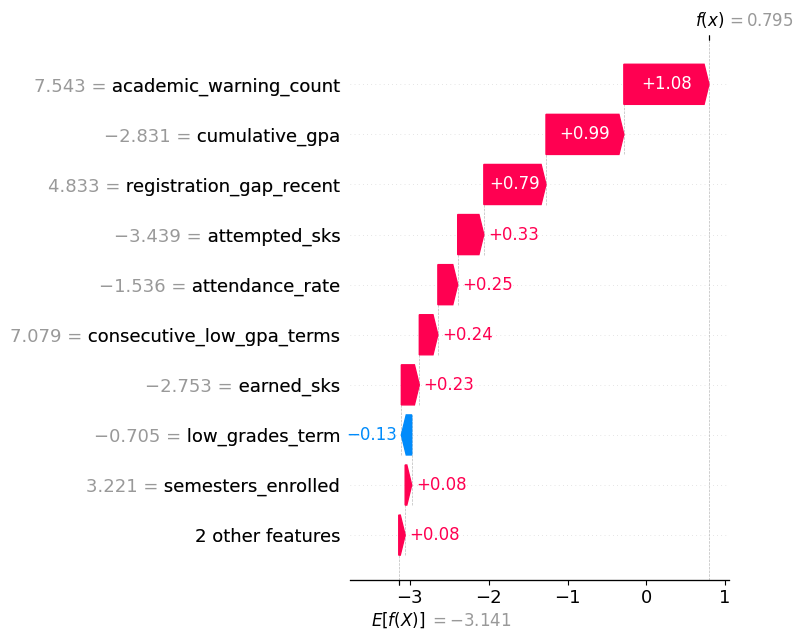

In [24]:
# Local: contoh satu mahasiswa dengan skor risiko paling tinggi pada TEST sintetis.
most_at_risk = ret_test.nlargest(1,'do_risk_score').copy()
X_local = pd.DataFrame(scaler.transform(most_at_risk[ret_features]),columns=ret_features)
local_shap = explainer(X_local)
print('Contoh student_id (sintetis):',most_at_risk.student_id.iloc[0])
print('Prediksi risiko DO:',f"{most_at_risk.do_risk_score.iloc[0]:.1%}")
print('Skala kontribusi SHAP = log-odds, bukan % probabilitas.')
shap.plots.waterfall(local_shap[0],max_display=10,show=False)
plt.tight_layout();plt.show()

**Cara membaca waterfall:**
1. Mulai dari `E[f(X)]`: output dasar model (*baseline*) pada data pembanding.
2. Setiap bar menambah/mengurangi skor **log-odds** berdasarkan fitur.
3. Akumulasi kontribusi menjadi `f(x)` untuk mahasiswa tersebut.
4. Skor probabilitas diperoleh dengan transformasi sigmoid; **bar SHAP bukan persentase**.

**Tugas tim:** tuliskan dua faktor yang menaikkan dan dua yang menurunkan skor untuk contoh sintetis. Jangan ubah menjadi label pribadi seperti "mahasiswa malas" atau klaim sebab-akibat.

### Langkah 5 — Prediksi → alokasi kapasitas dosen wali → tawaran dukungan

Skor risiko tidak berguna bila universitas tidak punya kapasitas layanan. Terapkan batas sederhana: tim hanya dapat meninjau **30 mahasiswa** pada putaran ini.

**Metric operasional:** `Recall@K = jumlah DO historis yang ada pada Top-K / total DO historis dalam holdout`. Ini mengukur kemampuan deteksi, **bukan jumlah DO yang berhasil dicegah**.

### Langkah 6. Ubah ranking menjadi alokasi layanan

Pada test historis, kita dapat membandingkan **Recall@15, @30, @60** untuk memahami kapasitas pembimbing. Pada term 8 (tanpa label matang), sistem hanya bisa menghasilkan **daftar review** dan tawaran layanan.

Tindakan tidak harus sama untuk setiap mahasiswa. Misalnya: review rencana studi, bantuan registrasi, atau percakapan privat untuk memahami hambatan belajar. **Dosen wali mengonfirmasi kondisi sebelum tindakan dilakukan**.

In [25]:
ADVISOR_SLOTS = 30    # TEAM CHALLENGE: bandingkan 15 vs 30 vs 60
ranking = ret_test.sort_values('do_risk_score',ascending=False)
num_events = int(ret_test[ret_target].sum())
for k in [15,30,60]:
    selected = ranking.head(k)
    detected = int(selected[ret_target].sum())
    print(f'K={k:>2} | Precision@K={detected/len(selected):.1%} | Recall@K={detected/max(num_events,1):.1%}')

# Data aktif term 8 belum memiliki label masa depan; hanya prediksi/penawaran layanan.
active = retention.loc[retention.term.eq(8)].copy()
active['do_risk_score'] = ret_model.predict_proba(active[ret_features])[:,1]

def support_offer(r):
    offers=[]
    if r.registration_gap_recent==1: offers.append('Bantu cek kendala registrasi')
    if r.cumulative_gpa<2.6: offers.append('Tawarkan coaching akademik')
    if r.progress_ratio<.70: offers.append('Bantu review rencana SKS')
    if r.attendance_rate<.65: offers.append('Check-in pribadi terkait hambatan belajar')
    return '; '.join(offers) if offers else 'Check-in dosen wali'

active['support_offer'] = active.apply(support_offer,axis=1)
advisor_queue = active.nlargest(ADVISOR_SLOTS,'do_risk_score')[[
    'student_id','program','do_risk_score','support_offer']]
display(advisor_queue.head(8))
advisor_queue.to_csv(OUTPUT/'advisor_queue_SIMULASI_RAHASIA.csv',index=False)

K=15 | Precision@K=53.3% | Recall@K=17.0%
K=30 | Precision@K=40.0% | Recall@K=25.5%
K=60 | Precision@K=35.0% | Recall@K=44.7%


,student_id,program,do_risk_score,support_offer
3417,STU-0577,Agribusiness Analytics,0.767172,Tawarkan coaching akademik
3197,STU-0320,Data Science for Agriculture,0.608067,Tawarkan coaching akademik; Bantu review renca...
3228,STU-0352,Data Science for Agriculture,0.586520,Tawarkan coaching akademik; Bantu review renca...
2983,STU-0076,Data Science for Agriculture,0.586323,Bantu cek kendala registrasi; Tawarkan coachin...
3188,STU-0311,Environmental Informatics,0.560519,Tawarkan coaching akademik; Bantu review renca...
3034,STU-0135,Environmental Informatics,0.553804,Bantu cek kendala registrasi; Tawarkan coachin...
3327,STU-0467,Environmental Informatics,0.546939,Tawarkan coaching akademik; Bantu review renca...
3537,STU-0712,Data Science for Agriculture,0.525947,Bantu cek kendala registrasi; Tawarkan coachin...


**Interpretasi queue:** urutan skor adalah **prioritas peninjauan**, bukan daftar orang yang pasti akan DO. Akses output harus terbatas pada petugas yang berwenang; jangan tampilkan nama/ID pada dashboard publik.

**Coba ubah:** bandingkan `ADVISOR_SLOTS=15` versus 30 pada output. Apa trade-off antara banyaknya mahasiswa yang dijangkau dan beban tindak lanjut dosen wali?

**Checkpoint 2A–B:** untuk satu baris pada SHAP waterfall, jelaskan 2 faktor yang menaikkan dan 2 yang menurunkan prediksi model. Usulkan tindakan **yang bersifat sukarela, rahasia, dan diverifikasi dosen wali**. Tidak boleh membatasi KRS/kelulusan berdasarkan skor DO.

## 2C. Collaborative Filtering: Rekomendasi Mata Kuliah (30 menit)

**Pertanyaan:** "Jika kelompok mahasiswa yang berhasil lulus mata kuliah X juga sering lulus Y, apakah Y menjadi opsi relevan bagi mahasiswa yang sudah lulus X?"

Kita memakai **item-based collaborative filtering**, bukan regresi/classification pada pilihan KRS. Sistem mempelajari kemiripan antarmata kuliah dari pola **kelulusan historis** mahasiswa.

**Alur ringkas:**

`Riwayat lulus mahasiswa` -> `Matriks 0/1` -> `Cosine similarity antarmata kuliah` -> `Peringkat` -> `Filter prasyarat + penawaran + dosen` -> **Top-5 opsi KRS**.

**Jaga interpretasi:** co-pass tidak memperhatikan urutan waktu, sehingga tidak memberi jaminan bahwa mahasiswa yang lulus X **akan** lulus Y. Ini penyaring relevansi historis, bukan model *probability of passing*.

### Langkah 1 — Siapkan matriks mahasiswa × mata kuliah lulus

Misalnya sebuah matriks biner:

| Mahasiswa | X | Y | Z |
|---|---:|---:|---:|
| A | 1 | 1 | 0 |
| B | 1 | 1 | 1 |
| C | 0 | 1 | 1 |

`1 = mata kuliah **sudah lulus**`, bukan sekadar pernah dipilih/diambil.

Gunakan data **semester 1–7** untuk melatih pola kemiripan. Semester 8 digunakan sebagai *holdout* evaluasi.

### Langkah 1. Bentuk matriks mahasiswa x mata kuliah

`1 = berhasil lulus` dan `0 = belum tercatat lulus`. Dalam data demo, lulus berarti `grade_points >= 2.0`; aturan tersebut hanya definisi sintetis.

**Penting:** hanya semester 1-7 dipakai untuk mempelajari kemiripan. Semester 8 sengaja disimpan untuk evaluasi di tahap berikutnya.

In [26]:
history = pd.read_csv(DATA/'academic_history.csv')
future_candidates = pd.read_csv(DATA/'next_term_candidates.csv')
prerequisites = pd.read_csv(DATA/'course_prerequisites.csv')
PASS_GRADE = 2.0       # Ambang LULUS HANYA untuk data sintetis

pass_train = history.loc[
    history.term.le(7) & history.grade_points.ge(PASS_GRADE),
    ['student_id','course_id']
].drop_duplicates()

student_course_matrix = pd.crosstab(pass_train.student_id, pass_train.course_id).gt(0).astype(int)
student_course_matrix = student_course_matrix.reindex(columns=courses.course_id,fill_value=0)

print('Dimensi matriks mahasiswa x mata kuliah:',student_course_matrix.shape)
display(student_course_matrix.iloc[:5,:10])

Dimensi matriks mahasiswa x mata kuliah: (718, 80)


course_id,C101,C102,C103,C104,C105,C106,C107,C108,C109,C110
student_id,,,,,,,,,,
STU-0001,1,0,0,1,1,1,0,1,0,1
STU-0002,0,0,0,0,0,0,0,0,0,0
STU-0003,0,0,0,0,0,0,0,0,0,0
STU-0004,0,0,0,0,0,0,0,0,0,0
STU-0005,1,1,0,0,0,0,0,1,0,0


**Baca hasilnya:** baris adalah mahasiswa, kolom adalah mata kuliah. Nilai 0 bukan bukti mahasiswa gagal; bisa juga **belum pernah mengambil** mata kuliah tersebut.

### Langkah 2 — Hitung *item-item cosine similarity*

Bila dua mata kuliah sering sama-sama lulus pada mahasiswa yang sama, vektor kolomnya lebih mirip. Fungsi `cosine_similarity` menghasilkan skor **0–1** pada matriks biner non-negatif ini.

Berbeda dengan *classifier*, kita **tidak memiliki target y** untuk melatih cosine similarity. Ini adalah metode collaborative filtering berbasis interaksi historis.

### Langkah 2. Hitung kemiripan dengan cosine similarity

Bayangkan dua mata kuliah sebagai dua kolom 0/1. Jika sering bernilai 1 untuk mahasiswa yang sama, pola keduanya mirip.

**Hasil cosine similarity** berada pada 0-1 untuk data biner non-negatif ini: makin tinggi berarti pola kelulusan tercatat makin mirip. `cosine_similarity` **tidak mempunyai target y** seperti regresi/klasifikasi; ini pendekatan berbasis pola interaksi historis.

In [27]:
course_ids = student_course_matrix.columns.to_list()
similarity = pd.DataFrame(
    cosine_similarity(student_course_matrix.T),index=course_ids,columns=course_ids
)
np.fill_diagonal(similarity.values,0)  # Jangan merekomendasikan course karena identik dengan dirinya.

EXAMPLE_COURSE = 'C406'  # Machine Learning (Data Science for Agriculture)
course_name_map = courses.set_index('course_id').course_name.to_dict()
similar = similarity.loc[EXAMPLE_COURSE].nlargest(5)
example_rows=[]
for other_course,sim in similar.items():
    both = int(((student_course_matrix[EXAMPLE_COURSE]==1) &
                (student_course_matrix[other_course]==1)).sum())
    passed_x = int(student_course_matrix[EXAMPLE_COURSE].sum())
    example_rows.append({
        'jika_lulus':course_name_map[EXAMPLE_COURSE],
        'juga_lulus':course_name_map[other_course],
        'co_pass_students':both,
        'co_pass_rate_among_X':round(both/max(passed_x,1),3),
        'cosine_similarity':round(sim,3)
    })
display(pd.DataFrame(example_rows))

,jika_lulus,juga_lulus,co_pass_students,co_pass_rate_among_X,cosine_similarity
0,Machine Learning,Time Series Analytics,41,0.494,0.703
1,Machine Learning,Data Fundamentals,61,0.735,0.630
2,Machine Learning,Applied Optimization,60,0.723,0.620
3,Machine Learning,Probability & Statistics,63,0.759,0.602
4,Machine Learning,Computer Vision for Crops,48,0.578,0.555


**Cara membaca hasil contoh:**
- `co_pass_students`: jumlah mahasiswa historis yang tercatat lulus kedua mata kuliah.
- `co_pass_rate_among_X`: proporsi mahasiswa yang lulus X dan juga tercatat lulus Y, **tanpa melihat urutan**.
- `cosine_similarity`: kemiripan pola mahasiswa lulus antara X dan Y.

**Jangan menyebut co-pass rate sebagai probabilitas lulus Y di masa depan.** Popularitas mata kuliah, kurikulum, dan cohort ikut memengaruhi hasil.

> **Jelaskan dengan benar:** `co_pass_rate_among_X` adalah proporsi historis mahasiswa yang tercatat lulus X dan juga pernah lulus Y, **tanpa membedakan urutan**. Jadi metrik ini tidak bisa diklaim sebagai `P(akan lulus Y | baru lulus X)`.

### Langkah 3 — Prasyarat wajib menggunakan logika **AND**

Contoh katalog sintetis:

- **C410 — Time Series Analytics** hanya dapat direkomendasikan bila **C406 — Machine Learning DAN C404 — Probability & Statistics** **keduanya** telah lulus.
- **C407 — Data Engineering** butuh **C403 — Data Fundamentals DAN C401 — Intro to Programming**.

Kita menyimpan aturan dalam **tabel relasi**, bukan memaksa semua prasyarat masuk satu kolom teks.

### Langkah 3. Pasang filter akademik yang tidak boleh dilanggar

Misalnya mata kuliah Z memerlukan M **dan** N. Tidak cukup mahasiswa hanya lulus M. Karena itu prasyarat disimpan sebagai tabel yang bisa memiliki **lebih dari satu baris per mata kuliah**.

Gunakan operator himpunan `issubset()`: semua elemen prasyarat harus terdapat dalam daftar mata kuliah yang sudah lulus.

In [28]:
prereq_map = prerequisites.groupby('course_id').required_course_id.apply(set).to_dict()

def has_passed_prerequisites(course_id, passed_courses):
    needed = prereq_map.get(course_id,set())
    return needed.issubset(passed_courses)  # True jika SEMUA sudah lulus

for course_id in ['C410','C407','C110']:
    needed=sorted(prereq_map.get(course_id,set()))
    print(course_id,course_name_map[course_id], ' membutuhkan: ',
          ' DAN '.join(f'{c} ({course_name_map[c]})' for c in needed))

# Contoh demonstrasi AND: mahasiswa yang baru lulus salah satu tidak bisa ambil C410.
print('Hanya lulus C406 -> boleh C410?',has_passed_prerequisites('C410',{'C406'}))
print('Lulus C406 DAN C404 -> boleh C410?',has_passed_prerequisites('C410',{'C406','C404'}))
assert not has_passed_prerequisites('C410',{'C406'})
assert has_passed_prerequisites('C410',{'C406','C404'})

C410 Time Series Analytics  membutuhkan:  C404 (Probability & Statistics) DAN C406 (Machine Learning)
C407 Data Engineering  membutuhkan:  C401 (Intro to Programming) DAN C403 (Data Fundamentals)
C110 Business Intelligence  membutuhkan:  C104 (Statistics for Business) DAN C106 (Business Data Analysis)
Hanya lulus C406 -> boleh C410? False
Lulus C406 DAN C404 -> boleh C410? True


**Cara membaca percobaan AND:**
- Hanya C406 lulus -> C410 **belum boleh diambil**.
- C406 **dan** C404 lulus -> syarat C410 **terpenuhi**.

Ini *hard rule*. Skor collaborative filtering setinggi apa pun **tidak dapat menggugurkan aturan prasyarat**.

### Langkah 4 — Uji recommender dengan semester 8 sebagai data masa depan

Kita memakai histori lulus sampai semester 7 untuk ranking, lalu menguji apakah mata kuliah yang direkomendasikan **beririsan** dengan mata kuliah yang ternyata berhasil diluluskan pada semester 8.

Sebagai pembanding, gunakan **baseline popularitas**: merekomendasikan mata kuliah yang paling banyak diluluskan cohort historis.

**Precision@3:** proporsi maksimal 3 rekomendasi yang benar-benar ada di daftar lulus semester 8 setelah filter prasyarat. Ini adalah ukuran kecocokan historis, **bukan ukuran keberhasilan akademik sesudah menggunakan sistem**.

### Langkah 4. Evaluasi dengan data semester berikutnya

Kita membuat rekomendasi hanya dari histori sampai term 7, kemudian menguji apakah Top-3 beririsan dengan daftar mata kuliah yang **berhasil diluluskan** pada term 8.

**Precision@3 = (jumlah rekomendasi yang sesuai ground truth) / (maksimal 3 rekomendasi)**. Bandingkan dengan **baseline popularitas**. Nilai tinggi menunjukkan kecocokan historis yang lebih baik pada kelompok yang diuji, **bukan** bukti peningkatan keberhasilan belajar atau dampak rekomendasi.

Keterbatasan evaluasi: mahasiswa dapat berhasil pada mata kuliah yang tidak ada dalam Top-3, dan evaluasi hanya memakai subset dengan outcome lulus yang tersedia. Saat produksi, tambahkan evaluasi coverage, diversity, fairness, dan kualitas penjelasan.

In [29]:
# Profil yang tersedia SEBELUM semester 8 (hindari information leakage).
passed_by_student_t7 = pass_train.groupby('student_id').course_id.apply(set).to_dict()
passed_in_term8 = history.loc[
    history.term.eq(8) & history.grade_points.ge(PASS_GRADE)
].groupby('student_id').course_id.apply(set).to_dict()
course_popularity = pass_train.groupby('course_id').student_id.nunique().to_dict()
student_program = students.set_index('student_id').program.to_dict()

# Sederhana: rekomendasi murni dari mean kemiripan dengan course yang SUDAH lulus.
def cf_scores(candidate_ids,passed_ids):
    if not candidate_ids or not passed_ids:
        return pd.Series(0.0,index=candidate_ids)
    return similarity.reindex(index=candidate_ids,columns=list(passed_ids)).fillna(0).mean(axis=1)

records=[]
# Untuk kecepatan workshop, evaluasi subset hingga 300 mahasiswa dengan data uji positif.
for sid in sorted(passed_in_term8)[:300]:
    prior=passed_by_student_t7.get(sid,set())
    if not prior: continue
    options=courses.loc[courses.program.eq(student_program[sid]),'course_id'].to_list()
    eligible_courses=[cid for cid in options if cid not in prior and
                      has_passed_prerequisites(cid,prior)]
    truth=passed_in_term8[sid].intersection(eligible_courses)
    if not truth: continue
    scores=cf_scores(eligible_courses,prior)
    cf_top=set(scores.sort_values(ascending=False).head(3).index)
    pop_top=set(sorted(eligible_courses,key=lambda cid:course_popularity.get(cid,0),reverse=True)[:3])
    denom=min(3,len(eligible_courses))
    records.append({'student_id':sid,
                    'cf_p3':len(cf_top.intersection(truth))/denom,
                    'pop_p3':len(pop_top.intersection(truth))/denom})

cf_eval=pd.DataFrame(records)
assert len(cf_eval)>0, 'Tidak ada data evaluasi; periksa aturan prasyarat dan histori kelulusan.'
print('Mahasiswa evaluasi:',len(cf_eval))
print(f"Collaborative Filtering Precision@3: {cf_eval.cf_p3.mean():.1%}")
print(f"Popularity baseline Precision@3: {cf_eval.pop_p3.mean():.1%}")
print('Ini adalah evaluasi offline sintetis; CF tidak wajib mengalahkan baseline.')

Mahasiswa evaluasi: 298
Collaborative Filtering Precision@3: 22.6%
Popularity baseline Precision@3: 22.0%
Ini adalah evaluasi offline sintetis; CF tidak wajib mengalahkan baseline.


**Interpretasi:** jika Precision@3 collaborative filtering hampir sama dengan baseline popularitas, jangan memaksakan klaim "AI lebih bagus". Bisa jadi data terlalu kecil, pola kelulusan sangat mengikuti kurikulum, atau pendekatan sederhana memang sudah kuat. Diskusikan perbaikan fitur/algoritma **setelah** menguji baseline.

### Langkah 5 — Filter KRS + kapasitas dosen (output Lab 1) lalu ranking

**Jangan pernah mengganti aturan akademik dengan skor ML.** Filter wajib dilakukan sebelum ranking:

1. Mahasiswa belum pernah **lulus** mata kuliah tersebut.
2. **Semua** prasyarat sudah lulus.
3. Mata kuliah tersedia di term 9, tingkatan mahasiswa diizinkan.
4. Ada section **dengan dosen yang benar-benar ditugaskan** (Lab 1).
5. Penanda kapasitas simulasi masih mengizinkan penawaran. Pada implementasi riil, kapasitas KRS harus dicek **live**, termasuk bentrok jadwal dan batas SKS mahasiswa.

Setelah kandidat lolos, urutkan berdasarkan collaborative filtering. Kalau tidak ada riwayat kelulusan (*cold start*), gunakan baseline popularitas **sebagai fallback yang transparan**.

### Langkah 5. Rekomendasikan hanya mata kuliah yang feasible

**Urutan yang benar:**
1. Filter **prasyarat sudah lulus**.
2. Hapus mata kuliah yang sudah lulus.
3. Pastikan **offered** dan level diizinkan.
4. Pastikan **ada section berdosen** dari Lab 1 dan kapasitas penawaran simulasi tidak nol.
5. **Baru urutkan** berdasarkan skor CF; gunakan popularitas jika belum ada histori kelulusan (*cold start*).

**Belum dimodelkan:** bentrok jadwal, batas SKS per mahasiswa, status mahasiswa yang khusus, dan reservasi kursi real-time. Sistem KRS resmi harus memeriksa semuanya.

In [30]:
passed_by_student_t8 = history.loc[
    history.term.le(8) & history.grade_points.ge(PASS_GRADE)
].groupby('student_id').course_id.apply(set).to_dict()

def recommend_courses(student_id, supply_plan, top_n=5):
    """1) Filter prasyarat & supply, 2) ranking item-item CF, 3) tampilkan alasan."""
    passed = passed_by_student_t8.get(student_id,set())
    candidate = future_candidates.loc[future_candidates.student_id.eq(student_id)].copy()
    if candidate.empty:
        return candidate

    candidate = candidate.merge(supply_plan[['course_id','assigned_sections']],on='course_id',how='left')
    candidate['assigned_sections'] = candidate.assigned_sections.fillna(0).astype(int)
    candidate['prereq_ok'] = candidate.course_id.apply(lambda cid:has_passed_prerequisites(cid,passed))
    candidate['already_passed'] = candidate.course_id.isin(passed)
    eligible = candidate.loc[
        (~candidate.already_passed) & candidate.prereq_ok &
        candidate.level_allowed.eq(1) & candidate.offered.eq(1) &
        candidate.has_capacity.eq(1) & candidate.assigned_sections.gt(0)
    ].copy()
    if eligible.empty:
        return eligible

    eligible['cf_score'] = cf_scores(eligible.course_id.to_list(),passed).to_numpy()
    eligible['popularity'] = eligible.course_id.map(course_popularity).fillna(0)
    eligible['method'] = 'Item-item collaborative filtering' if passed else 'Popularity fallback (cold start)'
    eligible = eligible.sort_values(['cf_score','popularity'],ascending=False).head(top_n)
    return eligible

STUDENT_ID = 'STU-0003'   # SILAKAN GANTI
recommendations = recommend_courses(STUDENT_ID,staffing_plan,top_n=5)
print('Mahasiswa:',STUDENT_ID,'| Lulus historis:',len(passed_by_student_t8.get(STUDENT_ID,set())))
if recommendations.empty:
    print('Tidak ada kandidat eligible pada semester 9. Coba ID lain atau cek kapasitas/prasyarat.')
else:
    display(recommendations[['course_id','course_name','credits','cf_score',
                             'assigned_sections','method']])
    recommendations.to_csv(OUTPUT/f'course_recommendation_{STUDENT_ID}_simulasi.csv',index=False)

Mahasiswa: STU-0003 | Lulus historis: 10


,course_id,course_name,credits,cf_score,assigned_sections,method
11,C312,Environmental Analytics Project,3,0.587744,2,Item-item collaborative filtering
5,C306,Climate Data Analysis,3,0.530850,1,Item-item collaborative filtering
1,C302,Ecology Fundamentals,3,0.520824,2,Item-item collaborative filtering
13,C314,Data Visualization,3,0.514981,2,Item-item collaborative filtering
16,C317,Applied Research Methods,2,0.435722,2,Item-item collaborative filtering


**Cara membaca Top-5:**
- `cf_score` adalah skor kemiripan historis, **bukan probabilitas kelulusan**.
- `assigned_sections > 0` berarti ada penugasan dosen pada rencana Lab 1, **bukan jaminan kursi masih tersedia ketika KRS dibuka**.
- Jika Top-5 tidak tersedia karena seluruh kelas penuh atau syarat gagal, rekomendasi **boleh kosong**. Lebih aman daripada meloloskan mata kuliah yang tidak eligible.

### Langkah 6 — Mengapa suatu mata kuliah direkomendasikan?

Untuk setiap course teratas, tampilkan 1–2 mata kuliah yang **sudah lulus** dengan cosine similarity tertinggi sebagai alasan yang dapat dipahami mahasiswa/dosen wali. Ini adalah *similarity explanation*, bukan pernyataan kausal dan bukan SHAP.

In [31]:
passed=passed_by_student_t8.get(STUDENT_ID,set())
for row in recommendations.itertuples(index=False):
    support = similarity.loc[row.course_id,list(passed)].nlargest(2) if passed else pd.Series(dtype=float)
    anchors = ', '.join(course_name_map[c] for c in support.index if support[c]>0)
    anchors = anchors or 'fallback popularitas / kemiripan historis terbatas'
    needed=sorted(prereq_map.get(row.course_id,set()))
    pre_txt=', '.join(course_name_map[c] for c in needed) if needed else 'tidak ada'
    print(f"{row.course_name} | cf={row.cf_score:.3f} | mirip dengan: {anchors} | prasyarat terpenuhi: {pre_txt}")

Environmental Analytics Project | cf=0.588 | mirip dengan: Remote Sensing, Environmental Statistics | prasyarat terpenuhi: tidak ada
Climate Data Analysis | cf=0.531 | mirip dengan: Remote Sensing, Environmental Statistics | prasyarat terpenuhi: tidak ada
Ecology Fundamentals | cf=0.521 | mirip dengan: Remote Sensing, GIS Foundations | prasyarat terpenuhi: tidak ada
Data Visualization | cf=0.515 | mirip dengan: Remote Sensing, GIS Foundations | prasyarat terpenuhi: tidak ada
Applied Research Methods | cf=0.436 | mirip dengan: Operations Research, Remote Sensing | prasyarat terpenuhi: tidak ada


**Interpretasi alasan:** "mirip dengan kursus yang sudah lulus" adalah alasan berbasis *co-pass*, bukan penilaian atas kualitas mahasiswa atau rekomendasi dosen wali yang bersifat final. Tunjukkan prasyarat yang terpenuhi secara eksplisit.

**Checkpoint 2C — Diskusi tim**

- Bandingkan dua `STUDENT_ID`: apakah Top-5 berbeda? Mengapa?
- Apakah `Precision@3` CF lebih baik dari popularitas? Jika tidak, bagaimana cara memperbaiki kualitas data/model?
- Kenapa mahasiswa yang berisiko DO **tidak otomatis dilarang** mengambil mata kuliah?
- Apa yang terjadi jika satu mata kuliah favorit kehabisan **dosen**, walaupun skor CF tinggi?

---
## 2D. Executive Challenge (15 menit)

**Situasi:** kapasitas mengajar dosen berkurang 20%, sedangkan dosen wali hanya mampu melakukan 30 review proaktif pada putaran ini.

**5 tim × 4 peserta.** Setiap tim menyiapkan keputusan singkat:

1. **Demand–Supply:** mata kuliah/prodi dengan gap terbesar, rekomendasi pemenuhan supply.
2. **Student Success:** kapasitas penanganan dan opsi dukungan yang aman secara privasi.
3. **Course Recommender:** contoh 1 mahasiswa dengan rekomendasi yang memenuhi semua prasyarat dan kapasitas.
4. **Validasi ke depan:** 1 asumsi yang harus dicek sebelum sistem dipakai sungguhan.

**Format presentasi:** 1 menit per tim—keputusan, bukti angka, dan batasan model.

## 2D. Executive Challenge: satu keputusan per tim (15 menit)

**Skenario:** kapasitas mengajar dosen berkurang 20%, dan kapasitas review dosen wali dibatasi 30 kasus.

Setiap tim menyampaikan dalam **60 detik**:
1. **Demand-Supply:** mata kuliah atau program studi mana paling memerlukan solusi kapasitas?
2. **Student Support:** apa arti membatasi review ke 30 mahasiswa dan dukungan apa yang relevan?
3. **Course Recommendation:** beri satu contoh Top-5 yang **lolos prasyarat dan memiliki section berdosen**.
4. **Batasan:** sebutkan satu data/aturan yang perlu divalidasi sebelum pilot.

> Penutup yang kuat: "Apa keputusan berbeda yang bisa dibuat setelah melihat output AI, dibanding hanya melihat dashboard deskriptif?"

In [32]:
summary = pd.DataFrame({
    'Skenario':['Supply normal',f'Supply -{SUPPLY_LOSS:.0%}'],
    'Forecast pendaftaran':[int(staffing_plan.forecast_demand.sum())]*2,
    'Section dengan dosen':[int(staffing_plan.assigned_sections.sum()),int(shock_plan.assigned_sections.sum())],
    'Demand belum terlayani':[int(staffing_plan.unserved_demand.sum()),int(shock_plan.unserved_demand.sum())]
})
display(summary)
print('Slot review dosen wali:',ADVISOR_SLOTS)
print('Jumlah course eligible untuk mahasiswa contoh:',len(recommendations))

normal_options = recommend_courses(STUDENT_ID,staffing_plan,top_n=10)
shock_options = recommend_courses(STUDENT_ID,shock_plan,top_n=10)
print('Kandidat Top-10 normal:',normal_options.course_id.to_list())
print('Kandidat Top-10 saat supply shock:',shock_options.course_id.to_list())

,Skenario,Forecast pendaftaran,Section dengan dosen,Demand belum terlayani
0,Supply normal,2006,136,184
1,Supply -20%,2006,99,828


Slot review dosen wali: 30
Jumlah course eligible untuk mahasiswa contoh: 5
Kandidat Top-10 normal: ['C312', 'C306', 'C302', 'C314', 'C317', 'C319', 'C320', 'C313']
Kandidat Top-10 saat supply shock: ['C312', 'C302', 'C314', 'C317', 'C319', 'C320']


### Templat insight untuk presentasi kelompok

Salin dan lengkapi tiga pernyataan ini dari output notebook, bukan dari slide PPT:

**Insight 1 (perencanaan):** "Pada simulasi semester 9, area dengan gap terbesar adalah **[...]**, terutama karena **[...]**. Kami menyarankan **[...]**."

**Insight 2 (layanan mahasiswa):** "Dengan kapasitas **[...]** review dosen wali, model membantu mengurutkan tindak lanjut. Kami menyarankan tawaran **[...]** dengan pemeriksaan manusia dan akses terbatas."

**Insight 3 (KRS):** "Untuk mahasiswa sintetis **[...]**, rekomendasi teratas adalah **[...]** karena pola historis **[...]** dan semua prasyarat terpenuhi. Kami masih harus mengecek **[...]**."

**Satu pertanyaan untuk penutup:** "Jika metrik offline tampak bagus tetapi data semester berikutnya berubah, sistem seperti apa yang dibutuhkan untuk memonitor penurunan kualitas?"

---
# Ringkasan: Apa yang sudah kita bangun?

| Modul | Teknik | Output teknis | Keputusan manusia |
|---|---|---|---|
| Forecast demand | Random Forest Regression | Jumlah perkiraan pendaftaran / mata kuliah | Rencana kebutuhan section |
| Lecturer capacity (asumsi) | Hitung SKS + alokasi per prodi | Estimasi section dan gap | Perencanaan kapasitas, bukan penjadwalan final |
| Risiko DO | Logistic Regression + SHAP | Skor prioritas dan alasan model | Tawaran dukungan akademik yang aman |
| Course recommender | Item-based Collaborative Filtering | Kandidat yang sudah disaring + skor kemiripan | Alternatif KRS untuk ditinjau mahasiswa/dosen wali |

**Bukan hasil dari workshop:** penugasan dosen individual, sistem penjadwalan optimal, sistem KRS live, keputusan DO otomatis, atau pembuktian bahwa intervensi menyebabkan penurunan DO.

### Jika akan dijadikan sistem produksi: 'What Next?'

- **Batch prediction** cocok untuk forecast semesteran dan prioritas review berkala: jalankan scoring berkala dan simpan hasil di database untuk dashboard.
- **API on-the-fly** cocok ketika rekomendasi KRS perlu dihitung berdasarkan status prasyarat, kursi, dan kebijakan terbaru.
- **Hybrid**: hitung kemiripan CF / forecast secara batch, lalu gunakan API untuk filter eligibility dan ketersediaan kursi yang mutakhir.
- Tambahkan pengawasan akses, audit keputusan, validasi model pada periode baru, monitoring data drift, dan saluran koreksi oleh pembimbing/mahasiswa.

**Terima kasih.** ML bukan menggantikan penilaian akademik, melainkan membantu membuat keputusan yang lebih cepat, transparan, dan bisa diuji.